## The Social Foundation and Its Indicators of Shortfall

**Starting Notes**
1. For each step, I create a working copy of the dataframe for safety
2. I print intermediate dataframes to verify that each transformation works as expected

*Reading all the files for social data*
- Import pandas 
- Import glob - tool for searching files with patterns
- Find all files that starts with *soc* and ends with *.csv* and store their name in a list
- Create one DataFrame with all the csv files

In [1335]:
import pandas as pd
import glob

soc_files = glob.glob("soc*.csv")

df_soc = pd.concat(map(pd.read_csv, soc_files), ignore_index=True)
df_soc

,domain,dimension,group,indicator,date,populationTotal,GNIperCap,value
0,social,social cohesion,World,socialSupport,2000,5.697045e+09,11511.032635,NaN
1,social,social cohesion,World,socialSupport,2001,5.769703e+09,11642.650443,NaN
2,social,social cohesion,World,socialSupport,2002,5.842014e+09,11782.637162,NaN
3,social,social cohesion,World,socialSupport,2003,5.913980e+09,12066.579184,NaN
4,social,social cohesion,World,socialSupport,2004,5.986016e+09,12533.044784,NaN
...,...,...,...,...,...,...,...,...
2111,social,equality,Top-20,racialInequality,2018,1.049559e+09,52506.855542,NaN
2112,social,equality,Top-20,racialInequality,2019,1.055075e+09,53135.856588,NaN
2113,social,equality,Top-20,racialInequality,2020,1.058227e+09,50458.680722,NaN
2114,social,equality,Top-20,racialInequality,2021,1.059835e+09,53177.426297,NaN


*Keep only the data I need*
- Create working copies for safety
- Drop the columns domain, populationTotal and GNIperCap

In [1336]:
df_soc_1 = df_soc.copy()

df_soc_1 = df_soc_1.drop(columns=["domain", "populationTotal", "GNIperCap"])
df_soc_1

,dimension,group,indicator,date,value
0,social cohesion,World,socialSupport,2000,NaN
1,social cohesion,World,socialSupport,2001,NaN
2,social cohesion,World,socialSupport,2002,NaN
3,social cohesion,World,socialSupport,2003,NaN
4,social cohesion,World,socialSupport,2004,NaN
...,...,...,...,...,...
2111,equality,Top-20,racialInequality,2018,NaN
2112,equality,Top-20,racialInequality,2019,NaN
2113,equality,Top-20,racialInequality,2020,NaN
2114,equality,Top-20,racialInequality,2021,NaN


*Drop rows with NaN values*
- Drop rows where *value = NaN*

In [1337]:
df_soc_2 = df_soc_1.copy()

df_soc_2 = df_soc_2.dropna(subset=["value"])
df_soc_2

,dimension,group,indicator,date,value
5,social cohesion,World,socialSupport,2005,20.469480
6,social cohesion,World,socialSupport,2006,20.885365
7,social cohesion,World,socialSupport,2007,23.907729
8,social cohesion,World,socialSupport,2008,24.203065
9,social cohesion,World,socialSupport,2009,22.283838
...,...,...,...,...,...
2019,equality,Top-20,genderGapIndex,2018,0.123582
2020,equality,Top-20,genderGapIndex,2019,0.119965
2021,equality,Top-20,genderGapIndex,2020,0.115727
2022,equality,Top-20,genderGapIndex,2021,0.115340


*Keep only the rows where the group is World*
- Copy to a new dataframe only the rows where *group = "World"*
- Then drop the column group

In [1338]:
df_soc_3 = df_soc_2.copy()

df_soc_3 = df_soc_3[df_soc_3["group"] == "World"].copy()
df_soc_3

,dimension,group,indicator,date,value
5,social cohesion,World,socialSupport,2005,20.469480
6,social cohesion,World,socialSupport,2006,20.885365
7,social cohesion,World,socialSupport,2007,23.907729
8,social cohesion,World,socialSupport,2008,24.203065
9,social cohesion,World,socialSupport,2009,22.283838
...,...,...,...,...,...
1950,equality,World,genderGapIndex,2018,0.363757
1951,equality,World,genderGapIndex,2019,0.356236
1952,equality,World,genderGapIndex,2020,0.352224
1953,equality,World,genderGapIndex,2021,0.350806


In [1339]:
df_soc_3 = df_soc_3.drop(columns="group")
df_soc_3

,dimension,indicator,date,value
5,social cohesion,socialSupport,2005,20.469480
6,social cohesion,socialSupport,2006,20.885365
7,social cohesion,socialSupport,2007,23.907729
8,social cohesion,socialSupport,2008,24.203065
9,social cohesion,socialSupport,2009,22.283838
...,...,...,...,...
1950,equality,genderGapIndex,2018,0.363757
1951,equality,genderGapIndex,2019,0.356236
1952,equality,genderGapIndex,2020,0.352224
1953,equality,genderGapIndex,2021,0.350806


*Find the first and the last year of each indicator*
- Sort the dataframe by dimension, indicator and date:
    The sorting ensures:
    - inside each dimension
    - inside each indicator
    - rows are ordered by date
- Exact the first row per group:
    - for each combination of (dimension, indicator) extract the first row in the sorted order, which is the earliest date for which I have valid data. The earliest value - earliest year - is saved in df_first_year
- Exact the last row per group:
    - for each combination of (dimension, indicator) extract the last row in the sorted order, which is the latest date for which I have valid data. The latest value - latest year - is saved in df_last_year
- Combine the two dates:
    - for each indicator in the first row add the earliest year and in the second row the lastest year
- Sort the final result first by dimension, then by indicator and then by date

Notes in code:
- as_index=False so that dimension and indicator become row indexes and not columns as it happens in the default behavior as_index=True
- ignore_index=True so that won't be created duplicate indexes

In [1340]:
df_soc_4 = df_soc_3.copy()

df_soc_4 = df_soc_4.sort_values(["dimension", "indicator", "date"])

df_first_year = df_soc_4.groupby(["dimension", "indicator"], as_index=False).first()
df_last_year  = df_soc_4.groupby(["dimension", "indicator"], as_index=False).last()

df_year_combination = pd.concat([df_first_year, df_last_year], ignore_index=True)

df_year_combination = df_year_combination.sort_values(["dimension", "indicator", "date"])
df_year_combination

,dimension,indicator,date,value
0,connectivity,internet,2000,6.475002
21,connectivity,internet,2022,64.175663
1,connectivity,publicTrans,2020,47.291095
22,connectivity,publicTrans,2020,47.291095
2,education,adultLiteracy,2000,76.865383
23,education,adultLiteracy,2022,83.848521
3,education,secondarySchool,2000,39.130233
24,education,secondarySchool,2022,63.089059
4,energy,energyAccess,2000,78.287833
25,energy,energyAccess,2022,91.487944


*Decode the column indicator*
- Create a decoding dictionary
    - each key is the coded indicator name (short version)
    - each value is the full descriptive name 
- Map the dictionary to the indicator column
    - .map() function checks each enty in the indicator column and replaces the coded value with the corresponding descriptive text from the dictionary

Notes:
The full descriptive indicator names were copied from Table 1 of the paper (URL: "https://www.nature.com/articles/s41586-025-09385-1/tables/1")

In [1341]:
decode_indicator = {
    "internet" : "Population not accessing the internet", 
    "publicTrans" : "Urban population lacking convenient access to public transport",
    "adultLiteracy" : "Young adult population (aged 21–23 years) with incomplete upper secondary education",
    "secondarySchool" : "Adult population (aged 15+ years) who are illiterate",
    "energyAccess" : "Population lacking access to electricity",
    "energyIndoor": "Population lacking access to clean fuels and technologies for cooking, heating and lighting",
    "genderGapIndex" : "Population-weighted score on the Gender Inequality Index (global gap between women and men in terms of reproductive health, empowerment and employment)",
    "undernourishment" : "Population undernourished",
    "foodInsecurity" : "Population with moderate to severe food insecurity",
    "under5death" : "Population living in countries with under-5 mortality rate exceeding 25 per 1,000 live births",
    "UHCindex" : "Population living in countries without high coverage of essential health services (Universal Health Coverage Index score less than 60 out of 100)",
    "urbanSlums" : "Urban population living in slums or informal settlements",
    "societalPoverty" : "Population living below the societal poverty line, set at half their country’s median household income or at least $15 a day",
    "youthNEET" : "Population of young people (aged 15–24 years) not in employment, education or training",
    "controlCorruption" : "Population stating that they perceive widespread corruption in government and business",
    "homicideOver5" : "Population living in countries with a homicide rate of 5 or more per 100,000",
    "govRegimes" : "Population living in countries governed by an autocratic regime",
    "socialSupport" : "Population stating that they are without someone to count on in times of trouble",
    "palma" : "Population living in countries with a Palma ratio of 2 or more (the income share of the richest 10% of people relative to the poorest 40%)",
    "drinkingH2O" : "Population lacking access to safely managed drinking water",
    "sanitation" : "Population lacking access to safely managed sanitation"
} 

In [1342]:
df_soc_5 = df_year_combination.copy()

df_soc_5["indicator"] = df_soc_5["indicator"].map(decode_indicator)
df_soc_5

,dimension,indicator,date,value
0,connectivity,Population not accessing the internet,2000,6.475002
21,connectivity,Population not accessing the internet,2022,64.175663
1,connectivity,Urban population lacking convenient access to ...,2020,47.291095
22,connectivity,Urban population lacking convenient access to ...,2020,47.291095
2,education,Young adult population (aged 21–23 years) with...,2000,76.865383
23,education,Young adult population (aged 21–23 years) with...,2022,83.848521
3,education,Adult population (aged 15+ years) who are illi...,2000,39.130233
24,education,Adult population (aged 15+ years) who are illi...,2022,63.089059
4,energy,Population lacking access to electricity,2000,78.287833
25,energy,Population lacking access to electricity,2022,91.487944


*Merge the rows with the same indicator*
- Extract the earliest (first) year for each indicator
    - the first row of each group is the earliest year, because the DataFrame is already sorted by date
    - columns date and values are renamed
- Extract the latest (last) year for each indicator
- Merge the earliest and latest records into one table, so that each indicator appears only once
- Reorder the columns of the table

In [1343]:
df_soc_6 = df_soc_5.copy()

df_first = df_soc_6.groupby(["dimension", "indicator"], as_index=False).first()
df_first = df_first.rename(columns={"date": "date_first", "value": "value_first"})

df_last = df_soc_6.groupby(["dimension", "indicator"], as_index=False).last()
df_last = df_last.rename(columns={"date": "date_last", "value": "value_last"})

df_soc_7 = df_first.merge(
    df_last[["dimension", "indicator", "date_last", "value_last"]],
    on=["dimension", "indicator"],
    how="inner"
)

df_soc_7 = df_soc_7[[
    "dimension",
    "indicator",
    "date_first",
    "date_last",
    "value_first",
    "value_last"
]]

df_soc_7

,dimension,indicator,date_first,date_last,value_first,value_last
0,connectivity,Population not accessing the internet,2000,2022,6.475002,64.175663
1,connectivity,Urban population lacking convenient access to ...,2020,2020,47.291095,47.291095
2,education,Adult population (aged 15+ years) who are illi...,2000,2022,39.130233,63.089059
3,education,Young adult population (aged 21–23 years) with...,2000,2022,76.865383,83.848521
4,energy,Population lacking access to clean fuels and t...,2000,2022,49.513196,74.084085
5,energy,Population lacking access to electricity,2000,2022,78.287833,91.487944
6,equality,Population-weighted score on the Gender Inequa...,2000,2022,0.456907,0.347205
7,food,Population undernourished,2000,2022,13.085805,9.619073
8,food,Population with moderate to severe food insecu...,2015,2022,22.241141,29.362668
9,health,Population living in countries with under-5 mo...,2000,2022,75.398098,42.615680


*Corrections in values*
- Complementary indicators (invert values): some indicators describe the opposite meaning compare to the original coded indicator, for example connectivity, education, energy, water. For these indicators, both value_first and value_last are corrected using *new value=100−old value*
- Indicators with values below 1 (rescale×100): some indicators percentages are below 1, for example equality, income and work, so to make them comparable they must be rescaled by multiplyint by 100, *new value=100×old value*

In [1344]:
df_soc_8 = df_soc_7.copy()

complementary_indicators = [
    "connectivity",
    "education",
    "energy",
    "water"
]
cols = ["value_first", "value_last"]

df_soc_8.loc[df_soc_8["dimension"].isin(complementary_indicators), cols] = \
    100 - df_soc_8.loc[df_soc_8["dimension"].isin(complementary_indicators), cols]

below_1_indicators = [
    "equality",
    "income and work"
]

mask = (df_soc_8["dimension"].isin(below_1_indicators)) & \
       (df_soc_8[cols].lt(1).any(axis=1)) # if at least one of the values is below 1 

df_soc_8.loc[mask, cols] = 100 * df_soc_8.loc[mask, cols]

df_soc_8

,dimension,indicator,date_first,date_last,value_first,value_last
0,connectivity,Population not accessing the internet,2000,2022,93.524998,35.824337
1,connectivity,Urban population lacking convenient access to ...,2020,2020,52.708905,52.708905
2,education,Adult population (aged 15+ years) who are illi...,2000,2022,60.869767,36.910941
3,education,Young adult population (aged 21–23 years) with...,2000,2022,23.134617,16.151479
4,energy,Population lacking access to clean fuels and t...,2000,2022,50.486804,25.915915
5,energy,Population lacking access to electricity,2000,2022,21.712167,8.512056
6,equality,Population-weighted score on the Gender Inequa...,2000,2022,45.690689,34.720511
7,food,Population undernourished,2000,2022,13.085805,9.619073
8,food,Population with moderate to severe food insecu...,2015,2022,22.241141,29.362668
9,health,Population living in countries with under-5 mo...,2000,2022,75.398098,42.615680


*Round values*
- Round all the values (value_first and value_last) to two decimal places
- Apply standard rounding:
    - If the third decimal digit is 0–4, the second decimal digit stays the same
    - If the third decimal digit is 5–9, the second decimal digit increases by one

In [1345]:
df_soc_9 = df_soc_8.copy()

df_soc_9 = df_soc_9.round({"value_first": 2, "value_last": 2})
df_soc_9

,dimension,indicator,date_first,date_last,value_first,value_last
0,connectivity,Population not accessing the internet,2000,2022,93.52,35.82
1,connectivity,Urban population lacking convenient access to ...,2020,2020,52.71,52.71
2,education,Adult population (aged 15+ years) who are illi...,2000,2022,60.87,36.91
3,education,Young adult population (aged 21–23 years) with...,2000,2022,23.13,16.15
4,energy,Population lacking access to clean fuels and t...,2000,2022,50.49,25.92
5,energy,Population lacking access to electricity,2000,2022,21.71,8.51
6,equality,Population-weighted score on the Gender Inequa...,2000,2022,45.69,34.72
7,food,Population undernourished,2000,2022,13.09,9.62
8,food,Population with moderate to severe food insecu...,2015,2022,22.24,29.36
9,health,Population living in countries with under-5 mo...,2000,2022,75.40,42.62


*Corrections in dimensions*
- Swap dimensions: list of dimentions where order should be reversed
- Create a helper order for each different dimention
- Swap only the dimentions form the swap_dimentions
- Sort using the new order
- Capitalize the first letter of each dimension name 

Note:
.transform(lambda x: x.max() - x): pandas operation used for reverse the order of the numbers in a group

In [1346]:
df_soc_10 = df_soc_9.copy()

swap_dimensions = [
    "energy",
    "food",
    "health",
    "peace and justice"
]

df_soc_10["order"] = df_soc_10.groupby("dimension").cumcount()

df_soc_10.loc[df_soc_10["dimension"].isin(swap_dimensions), "order"] = \
df_soc_10.loc[df_soc_10["dimension"].isin(swap_dimensions)].groupby("dimension")["order"].transform(lambda x: x.max() - x)

df_soc_10 = df_soc_10.sort_values(["dimension", "order"]).drop(columns="order")

df_soc_10

,dimension,indicator,date_first,date_last,value_first,value_last
0,connectivity,Population not accessing the internet,2000,2022,93.52,35.82
1,connectivity,Urban population lacking convenient access to ...,2020,2020,52.71,52.71
2,education,Adult population (aged 15+ years) who are illi...,2000,2022,60.87,36.91
3,education,Young adult population (aged 21–23 years) with...,2000,2022,23.13,16.15
5,energy,Population lacking access to electricity,2000,2022,21.71,8.51
4,energy,Population lacking access to clean fuels and t...,2000,2022,50.49,25.92
6,equality,Population-weighted score on the Gender Inequa...,2000,2022,45.69,34.72
8,food,Population with moderate to severe food insecu...,2015,2022,22.24,29.36
7,food,Population undernourished,2000,2022,13.09,9.62
10,health,Population living in countries without high co...,2000,2022,79.05,28.07


In [1347]:
df_soc_10["dimension"] = df_soc_10["dimension"].str.capitalize()

df_soc_10

,dimension,indicator,date_first,date_last,value_first,value_last
0,Connectivity,Population not accessing the internet,2000,2022,93.52,35.82
1,Connectivity,Urban population lacking convenient access to ...,2020,2020,52.71,52.71
2,Education,Adult population (aged 15+ years) who are illi...,2000,2022,60.87,36.91
3,Education,Young adult population (aged 21–23 years) with...,2000,2022,23.13,16.15
5,Energy,Population lacking access to electricity,2000,2022,21.71,8.51
4,Energy,Population lacking access to clean fuels and t...,2000,2022,50.49,25.92
6,Equality,Population-weighted score on the Gender Inequa...,2000,2022,45.69,34.72
8,Food,Population with moderate to severe food insecu...,2015,2022,22.24,29.36
7,Food,Population undernourished,2000,2022,13.09,9.62
10,Health,Population living in countries without high co...,2000,2022,79.05,28.07


*Final table*
- Convert the table header into a two-level stucture (pd.MultiIndex.from_tuples()):
    - Level 1: dimension, indicator, date, value
    - Level 2: first/last
- Apply visual styling to format the table

In [1348]:
df_display = df_soc_10.copy()

df_display.columns = pd.MultiIndex.from_tuples([
    ("dimension", ""),
    ("indicator", ""),
    ("date", "first"),
    ("date", "last"),
    ("value", "first"),
    ("value", "last"),
])

styled = (
    df_display.style

    .apply(lambda s: [
            'background-color: #1e1e1e' if i % 2 == 0 else 'background-color: #1e1e1e'
            for i in range(len(s))
        ], axis=0) #Apply uniform background shading

        # Format numeric columns (2 decimals)
        .format({
            ("value", "first"): "{:.2f}",
            ("value", "last"): "{:.2f}",
        })

        # remove ALL background-color and color settings
        .set_table_styles([
            # HEADER (top two rows)
            {"selector": "th",
             "props": [
                 ("font-size", "16px"), 
                 ("font-weight", "bold"),
                 ("padding", "8px"),
                 ("border", "1px solid #CCCCCC"),
                 ("background-color", "#1e1e1e"),
                ("text-align", "center"),
             ]},

            # BODY CELLS (all rows)
            {"selector": "td",
             "props": [
                 ("font-size", "17.5px"),
                 ("padding", "8px"),
                 ("border", "1px solid #CCCCCC"),
                 ("text-align", "left"),
                 ("white-space", "pre-wrap"),
                 ("max-width", "450px")
             ]},

            # LEFT-ALIGN INDICATOR COLUMN
            {"selector": "td:nth-child(2)",
             "props": [
                 ("text-align", "left"),
                 ("padding-left", "10px"),
                 ("padding-right", "10px")
             ]},
        ])
)

styled = styled.hide(axis="index")
styled



## The Ecological Ceiling and Its Indicators of Overshoot

*Reading all the files for social data*
- Import pandas 
- Import glob - tool for searching files with patterns
- Find all files that starts with *eco* and ends with *.csv* and store their name in a list
- Create one DataFrame with all the csv files

In [1349]:
import pandas as pd
import glob

soc_files = glob.glob("eco*.csv")

df_eco = pd.concat(map(pd.read_csv, soc_files), ignore_index=True)
df_eco

,domain,dimension,type,group,indicator,date,populationTotal,GNIperCap,value
0,ecological,climate change,global doughnut,World,co2_ppm,2000,NaN,NaN,368.96
1,ecological,climate change,global doughnut,World,co2_ppm,2001,NaN,NaN,370.57
2,ecological,climate change,global doughnut,World,co2_ppm,2002,NaN,NaN,372.58
3,ecological,climate change,global doughnut,World,co2_ppm,2003,NaN,NaN,375.14
4,ecological,climate change,global doughnut,World,co2_ppm,2004,NaN,NaN,376.95
...,...,...,...,...,...,...,...,...,...
1329,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2018,1.057622e+09,52596.852917,NaN
1330,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2019,1.063158e+09,53214.914280,NaN
1331,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2020,1.066320e+09,50530.945001,NaN
1332,ecological,ozone depletion,national aggregate,Top-20,ozone_footprint,2021,1.067927e+09,53260.809722,NaN


*Keep only the data I need*
- Drop the columns domain, populationTotal and GNIperCap

In [1350]:
df_eco_1 = df_eco.copy()

df_eco_1 = df_eco_1.drop(columns=["domain", "type","populationTotal", "GNIperCap"])
df_eco_1

,dimension,group,indicator,date,value
0,climate change,World,co2_ppm,2000,368.96
1,climate change,World,co2_ppm,2001,370.57
2,climate change,World,co2_ppm,2002,372.58
3,climate change,World,co2_ppm,2003,375.14
4,climate change,World,co2_ppm,2004,376.95
...,...,...,...,...,...
1329,ozone depletion,Top-20,ozone_footprint,2018,NaN
1330,ozone depletion,Top-20,ozone_footprint,2019,NaN
1331,ozone depletion,Top-20,ozone_footprint,2020,NaN
1332,ozone depletion,Top-20,ozone_footprint,2021,NaN


*Drop rows with NaN values*
- Drop rows where *value = NaN*

In [1351]:
df_eco_2 = df_eco_1.copy()

df_eco_2 = df_eco_2.dropna(subset=["value"])
df_eco_2

,dimension,group,indicator,date,value
0,climate change,World,co2_ppm,2000,368.960000
1,climate change,World,co2_ppm,2001,370.570000
2,climate change,World,co2_ppm,2002,372.580000
3,climate change,World,co2_ppm,2003,375.140000
4,climate change,World,co2_ppm,2004,376.950000
...,...,...,...,...,...
1236,ozone depletion,World,totalOzone,2017,283.746475
1237,ozone depletion,World,totalOzone,2018,286.320786
1238,ozone depletion,World,totalOzone,2019,279.557846
1239,ozone depletion,World,totalOzone,2020,281.959763


*Keep only the rows where the group is World*
- Copy to a new dataframe only the rows where *group = "World"*
- Then drop the column group

In [1352]:
df_eco_3 = df_eco_2.copy()

df_eco_3 = df_eco_3[df_eco_3["group"] == "World"].copy()
df_eco_3

,dimension,group,indicator,date,value
0,climate change,World,co2_ppm,2000,368.960000
1,climate change,World,co2_ppm,2001,370.570000
2,climate change,World,co2_ppm,2002,372.580000
3,climate change,World,co2_ppm,2003,375.140000
4,climate change,World,co2_ppm,2004,376.950000
...,...,...,...,...,...
1236,ozone depletion,World,totalOzone,2017,283.746475
1237,ozone depletion,World,totalOzone,2018,286.320786
1238,ozone depletion,World,totalOzone,2019,279.557846
1239,ozone depletion,World,totalOzone,2020,281.959763


In [1353]:
df_eco_3 = df_eco_3.drop(columns="group")
df_eco_3

,dimension,indicator,date,value
0,climate change,co2_ppm,2000,368.960000
1,climate change,co2_ppm,2001,370.570000
2,climate change,co2_ppm,2002,372.580000
3,climate change,co2_ppm,2003,375.140000
4,climate change,co2_ppm,2004,376.950000
...,...,...,...,...
1236,ozone depletion,totalOzone,2017,283.746475
1237,ozone depletion,totalOzone,2018,286.320786
1238,ozone depletion,totalOzone,2019,279.557846
1239,ozone depletion,totalOzone,2020,281.959763


*Find the first and the last year of each indicator*
- Sort the dataframe by dimension, indicator and date:
    The sorting ensures:
    - inside each dimension
    - inside each indicator
    - rows are ordered by date
- Exact the first row per group:
    - for each combination of (dimension, indicator) extract the first row in the sorted order, which is the earliest date for which I have valid data. The earliest value - earliest year - is saved in df_first_year
- Exact the last row per group:
    - for each combination of (dimension, indicator) extract the last row in the sorted order, which is the latest date for which I have valid data. The latest value - latest year - is saved in df_last_year
- Combine the two dates:
    - for each indicator in the first row add the earliest year and in the second row the lastest year
- Sort the final result first by dimension, then by indicator and then by date

Notes in code:
- as_index=False so that dimension and indicator become row indexes and not columns as it happens in the default behavior as_index=True
- ignore_index=True so that won't be created duplicate indexes

In [1354]:
df_eco_4 = df_eco_3.copy()

df_eco_4 = df_eco_4.sort_values(["dimension", "indicator", "date"])

df_first_year_eco = df_eco_4.groupby(["dimension", "indicator"], as_index=False).first()
df_last_year_eco = df_eco_4.groupby(["dimension", "indicator"], as_index=False).last()

df_year_combination_eco = pd.concat([df_first_year_eco, df_last_year_eco], ignore_index=True)

df_year_combination_eco = df_year_combination_eco.sort_values(["dimension", "indicator", "date"])
df_year_combination_eco

,dimension,indicator,date,value
0,air pollution,interhemAOD,2000,0.080000
20,air pollution,interhemAOD,2022,0.080000
1,biodiversity breakdown,extinction1900,2000,100.000000
21,biodiversity breakdown,extinction1900,2022,100.000000
2,biodiversity breakdown,hanppGtC,2000,14.600000
22,biodiversity breakdown,hanppGtC,2020,16.800000
3,biodiversity breakdown,hanpp_footprint,2017,1.944519
23,biodiversity breakdown,hanpp_footprint,2017,1.944519
4,biodiversity breakdown,species_footprint,2017,0.661259
24,biodiversity breakdown,species_footprint,2017,0.661259


*Decode the column indicator*
- Create a decoding dictionary
    - each key is the coded indicator name (short version)
    - each value is the full descriptive name 
- Map the dictionary to the indicator column
    - .map() function checks each enty in the indicator column and replaces the coded value with the corresponding descriptive text from the dictionary

Notes:
The full descriptive indicator names were copied from Table 1 of the paper (URL: "https://www.nature.com/articles/s41586-025-09385-1/tables/2")

In [1355]:
decode_indicator_eco = {
    "interhemAOD" : "Asymmetry between Earth’s hemispheres of sunlight reaching the surface, owing to differences in atmospheric particle concentration (at most 0.1 inter-hemispheric difference in Aerosol Optical Depth)",
    "extinction1900" : "Rate of species extinctions per million species years (at most 10 E/MSY)",
    "hanppGtC" : "Human appropriation of net primary productivity, billions of tonnes of carbon per year (at most 10% of 55.9 Gt C)",
    "chemicalsMt" : "Production of hazardous chemicals, millions of tonnes per year (at most 5% of the 1,200 Mt of total chemicals produced in year 2000)",
    "co2_ppm" : "Atmospheric carbon dioxide concentration, parts per million (at most 350 ppm CO2)",
    "erf_wm2" : "Human-induced radiative forcing at the top of the atmosphere, Watt per square metre (at most 1 W m−2)",
    "blueDev" : "Proportion of land area with human-induced disturbance of blue-water flow deviating from Holocene variability (at most 10.2%)",
    "soilDev" : "Proportion of land area with root-zone soil moisture deviating from Holocene variability (at most 11.1%)",
    "forestAreaMKM2" : "Area of forested land as a proportion of forest-covered land before human alteration (at least 75% of 64 million square kilometres)",
    "nitrogenMt" : "Nitrogen applied to land as fertilizer, millions of tonnes per year (at most 62 Mt per year)",
    "phosphorusMt" : "Phosphorus applied to land as fertilizer, millions of tonnes per year (at most 6.2 Mt per year)",
    "omega_a" : "Average saturation state of aragonite at the ocean surface (at least 80% of pre-industrial saturation state of 3.44 Ωarag)",
    "totalOzone" : "Concentration of ozone in the stratosphere, Dobson units (at most 5% decrease with respect to 1964–1980 value of 290 DU)"
}

In [1356]:
df_eco_5 = df_year_combination_eco.copy()

df_eco_5["indicator"] = df_eco_5["indicator"].map(decode_indicator_eco)
df_eco_5 = df_eco_5.reset_index(drop=True)

df_eco_5

,dimension,indicator,date,value
0,air pollution,Asymmetry between Earth’s hemispheres of sunli...,2000,0.080000
1,air pollution,Asymmetry between Earth’s hemispheres of sunli...,2022,0.080000
2,biodiversity breakdown,Rate of species extinctions per million specie...,2000,100.000000
3,biodiversity breakdown,Rate of species extinctions per million specie...,2022,100.000000
4,biodiversity breakdown,Human appropriation of net primary productivit...,2000,14.600000
5,biodiversity breakdown,Human appropriation of net primary productivit...,2020,16.800000
6,biodiversity breakdown,NaN,2017,1.944519
7,biodiversity breakdown,NaN,2017,1.944519
8,biodiversity breakdown,NaN,2017,0.661259
9,biodiversity breakdown,NaN,2017,0.661259


*Merge the rows with the same indicator*
- Extract the earliest (first) year for each indicator
    - the first row of each group is the earliest year, because the DataFrame is already sorted by date
    - columns date and values are renamed
- Extract the latest (last) year for each indicator
- Merge the earliest and latest records into one table, so that each indicator appears only once
- Reorder the columns of the table

In [1357]:
df_eco_6 = df_eco_5.copy()

df_first = df_eco_6.groupby(["dimension", "indicator"], as_index=False).first()
df_first = df_first.rename(columns={"date": "date_first", "value": "value_first"})

df_last = df_eco_6.groupby(["dimension", "indicator"], as_index=False).last()
df_last = df_last.rename(columns={"date": "date_last", "value": "value_last"})

df_eco_7 = df_first.merge(
    df_last[["dimension", "indicator", "date_last", "value_last"]],
    on=["dimension", "indicator"],
    how="inner"
)

df_eco_7 = df_eco_7[[
    "dimension",
    "indicator",
    "date_first",
    "date_last",
    "value_first",
    "value_last"
]]

df_eco_7

,dimension,indicator,date_first,date_last,value_first,value_last
0,air pollution,Asymmetry between Earth’s hemispheres of sunli...,2000,2022,0.080000,0.080000
1,biodiversity breakdown,Human appropriation of net primary productivit...,2000,2020,14.600000,16.800000
2,biodiversity breakdown,Rate of species extinctions per million specie...,2000,2022,100.000000,100.000000
3,chemical pollution,"Production of hazardous chemicals, millions of...",2000,2017,1186.000000,2276.000000
4,climate change,"Atmospheric carbon dioxide concentration, part...",2000,2022,368.960000,417.070000
5,climate change,Human-induced radiative forcing at the top of ...,2000,2022,1.768162,2.914968
6,freshwater disruption,Proportion of land area with human-induced dis...,2000,2005,0.178261,0.185959
7,freshwater disruption,Proportion of land area with root-zone soil mo...,2000,2014,15.434123,19.253297
8,land conversion,Area of forested land as a proportion of fores...,2000,2020,39.207563,38.272973
9,nutrient pollution,"Nitrogen applied to land as fertilizer, millio...",2000,2022,132.243271,194.338159


*Round values*
- Round all the values (value_first and value_last) to two decimal places
- Apply standard rounding:
    - If the third decimal digit is 0–4, the second decimal digit stays the same
    - If the third decimal digit is 5–9, the second decimal digit increases by one

In [1358]:
df_eco_8 = df_eco_7.copy()

df_eco_8 = df_eco_8.round({"value_first": 2, "value_last": 2})
df_eco_8

,dimension,indicator,date_first,date_last,value_first,value_last
0,air pollution,Asymmetry between Earth’s hemispheres of sunli...,2000,2022,0.08,0.08
1,biodiversity breakdown,Human appropriation of net primary productivit...,2000,2020,14.60,16.80
2,biodiversity breakdown,Rate of species extinctions per million specie...,2000,2022,100.00,100.00
3,chemical pollution,"Production of hazardous chemicals, millions of...",2000,2017,1186.00,2276.00
4,climate change,"Atmospheric carbon dioxide concentration, part...",2000,2022,368.96,417.07
5,climate change,Human-induced radiative forcing at the top of ...,2000,2022,1.77,2.91
6,freshwater disruption,Proportion of land area with human-induced dis...,2000,2005,0.18,0.19
7,freshwater disruption,Proportion of land area with root-zone soil mo...,2000,2014,15.43,19.25
8,land conversion,Area of forested land as a proportion of fores...,2000,2020,39.21,38.27
9,nutrient pollution,"Nitrogen applied to land as fertilizer, millio...",2000,2022,132.24,194.34


*Corrections in dimensions*
- Swap indicator order only for biodiversity breakdown
- Capitalize the first letter of each dimension name 

In [1359]:
df_eco_9 = df_eco_8.copy()

mask = df_eco_9["dimension"] == "biodiversity breakdown"

df_eco_9.loc[mask] = (
    df_eco_9.loc[mask].iloc[::-1].values
)

df_eco_9

,dimension,indicator,date_first,date_last,value_first,value_last
0,air pollution,Asymmetry between Earth’s hemispheres of sunli...,2000,2022,0.08,0.08
1,biodiversity breakdown,Rate of species extinctions per million specie...,2000,2022,100.00,100.00
2,biodiversity breakdown,Human appropriation of net primary productivit...,2000,2020,14.60,16.80
3,chemical pollution,"Production of hazardous chemicals, millions of...",2000,2017,1186.00,2276.00
4,climate change,"Atmospheric carbon dioxide concentration, part...",2000,2022,368.96,417.07
5,climate change,Human-induced radiative forcing at the top of ...,2000,2022,1.77,2.91
6,freshwater disruption,Proportion of land area with human-induced dis...,2000,2005,0.18,0.19
7,freshwater disruption,Proportion of land area with root-zone soil mo...,2000,2014,15.43,19.25
8,land conversion,Area of forested land as a proportion of fores...,2000,2020,39.21,38.27
9,nutrient pollution,"Nitrogen applied to land as fertilizer, millio...",2000,2022,132.24,194.34


In [1360]:
df_eco_9["dimension"] = df_eco_9["dimension"].str.capitalize()

df_eco_9

,dimension,indicator,date_first,date_last,value_first,value_last
0,Air pollution,Asymmetry between Earth’s hemispheres of sunli...,2000,2022,0.08,0.08
1,Biodiversity breakdown,Rate of species extinctions per million specie...,2000,2022,100.00,100.00
2,Biodiversity breakdown,Human appropriation of net primary productivit...,2000,2020,14.60,16.80
3,Chemical pollution,"Production of hazardous chemicals, millions of...",2000,2017,1186.00,2276.00
4,Climate change,"Atmospheric carbon dioxide concentration, part...",2000,2022,368.96,417.07
5,Climate change,Human-induced radiative forcing at the top of ...,2000,2022,1.77,2.91
6,Freshwater disruption,Proportion of land area with human-induced dis...,2000,2005,0.18,0.19
7,Freshwater disruption,Proportion of land area with root-zone soil mo...,2000,2014,15.43,19.25
8,Land conversion,Area of forested land as a proportion of fores...,2000,2020,39.21,38.27
9,Nutrient pollution,"Nitrogen applied to land as fertilizer, millio...",2000,2022,132.24,194.34


*Final table*
- Convert the table header into a two-level stucture (pd.MultiIndex.from_tuples()):
    - Level 1: dimension, indicator, date, value
    - Level 2: first/last
- Apply visual styling to format the table

In [1361]:
df_display_eco = df_eco_9.copy()

df_display_eco.columns = pd.MultiIndex.from_tuples([
    ("dimension", ""),
    ("indicator", ""),
    ("date", "first"),
    ("date", "last"),
    ("value", "first"),
    ("value", "last"),
])

styled_eco = (
    df_display_eco.style

    .apply(lambda s: [
            'background-color: #1e1e1e' if i % 2 == 0 else 'background-color: #1e1e1e'
            for i in range(len(s))
        ], axis=0)

        # Format numeric columns (2 decimals)
        .format({
            ("value", "first"): "{:.2f}",
            ("value", "last"): "{:.2f}",
        })

        # remove background-color and color settings
        .set_table_styles([
            # Header (top two rows)
            {"selector": "th",
             "props": [
                 ("font-size", "16px"), 
                 ("font-weight", "bold"),
                 ("padding", "8px"),
                 ("border", "1px solid #CCCCCC"),
                 ("background-color", "#1e1e1e"),
                ("text-align", "center"),
             ]},

            # Body cells
            {"selector": "td",
             "props": [
                 ("font-size", "17.5px"),
                 ("padding", "8px"),
                 ("border", "1px solid #CCCCCC"),
                 ("text-align", "left"),
                 ("white-space", "pre-wrap"),
                 ("max-width", "450px")
             ]},

            {"selector": "td:nth-child(2)",
             "props": [
                 ("text-align", "left"),
                 ("padding-left", "10px"),
                 ("padding-right", "10px")
             ]},
        ])
)

styled_eco = styled_eco.hide(axis="index")
styled_eco



## Country Clusters

*Trellis Plot for Ecological Overshoot*
- Load data
- Decode indicator column
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns and create a new column named *indicator_clean* 
- Group ordering 
    - group order: *Bottom-40 → Middle-40 → Top-20*
    - convert the group column to categorical variable with the explicit order
- Value preparation 
    - negative values are clamped to zero - negative bars are not plotted
    - store cleaned values
    - duplicate into *value_plot_visible* for plotting
- Visibility correction for *hanpp_footprint*, Bottom-40 group
    - hanpp_footprint value is extremely small, so it is boosted to 8% to remain visible in the barplots
- Indicator alphabetical ordering 
- Figure setup 
    - 2×3 grid
    - 3-color palette
    - define y-axis formatter
- Loop through indicators and create each subplot
- Layout and spacing between subplots
- Save trellis figure as "trellis_eco.png"

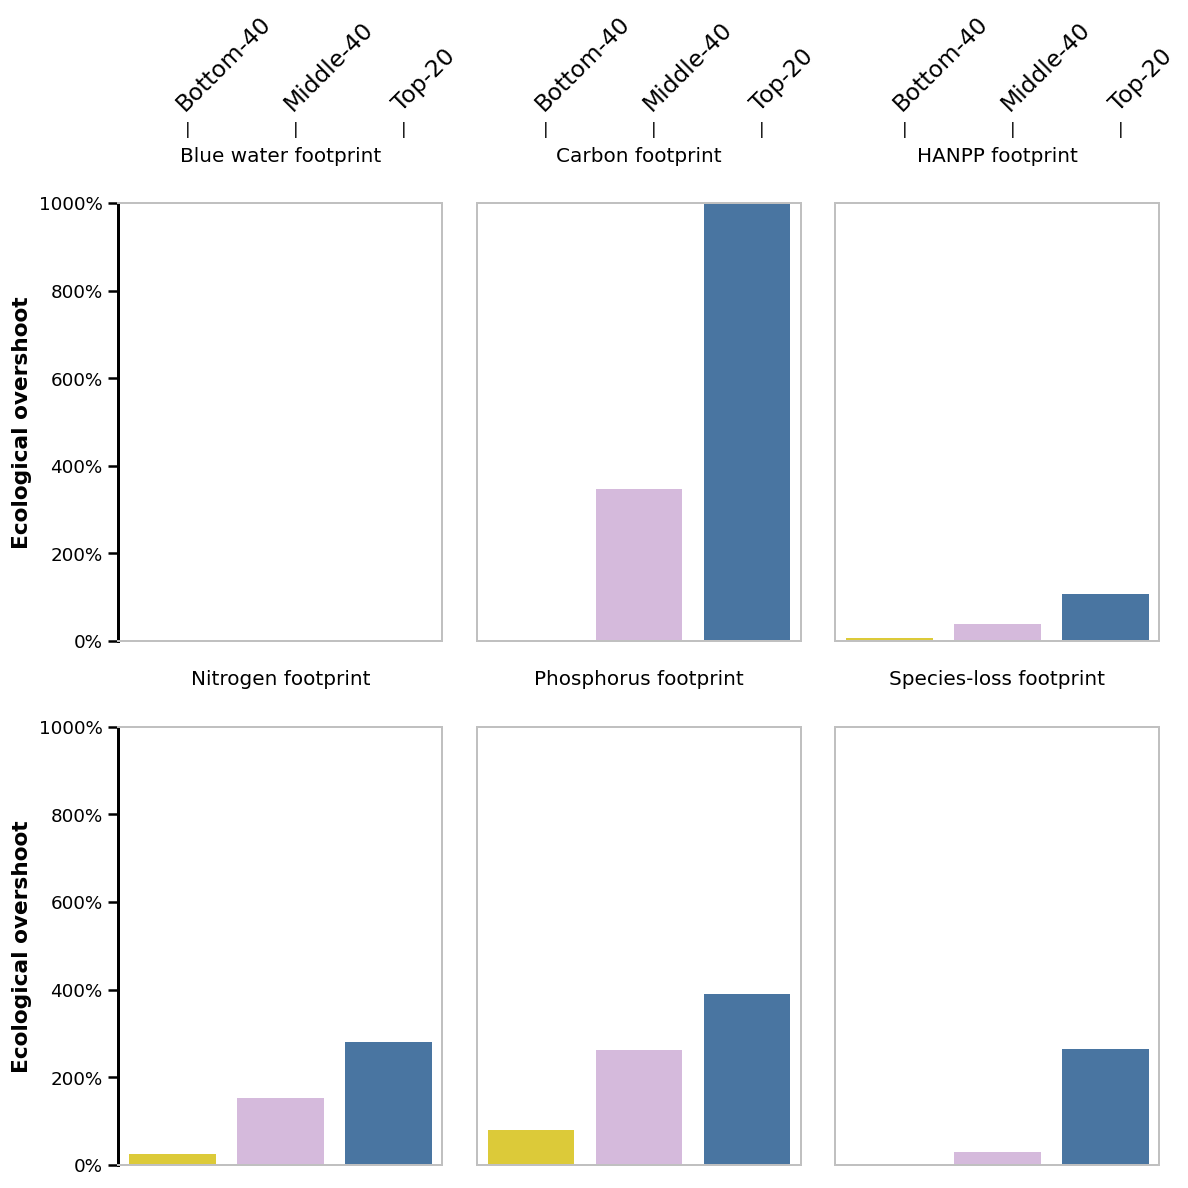

In [1362]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import Image
import warnings
warnings.simplefilter("ignore", FutureWarning)
 
df = pd.read_csv("12_20250515_groupDoughnutData_2017.csv")

indicator_map = {
    "blueH2O_footprint": "Blue water footprint",
    "co2_footprint": "Carbon footprint",
    "hanpp_footprint": "HANPP footprint",
    "N_footprint": "Nitrogen footprint",
    "P_footprint": "Phosphorus footprint",
    "species_footprint": "Species-loss footprint",
}

df = df[df["indicator"].isin(indicator_map.keys())].copy()
df["indicator_clean"] = df["indicator"].map(indicator_map)

order = ["Bottom-40", "Middle-40", "Top-20"]
df["group"] = pd.Categorical(df["group"], categories=order, ordered=True)

df["value_plot"] = df["shortfallOvershoot_pct"].clip(lower=0)

df["value_plot_visible"] = df["value_plot"]

mask_hanpp_b40 = (df["indicator"] == "hanpp_footprint") & (df["group"] == "Bottom-40")
df.loc[mask_hanpp_b40 & (df["value_plot"] > 0), "value_plot_visible"] = 8

indicators = sorted(df["indicator_clean"].unique())

# figure
plt.rcParams["figure.dpi"] = 120
fig, axes = plt.subplots(2, 3, figsize=(10, 10), constrained_layout=False)
axes = axes.flatten()

colors = ["#F7DF1E", "#D8B4E2", "#3A75B0"]

def percent_fmt(x, pos):
    return f"{int(x)}%"

# TRELLIS LOOP
for idx_ax, (ax, ind) in enumerate(zip(axes, indicators)):

    sub = df[df["indicator_clean"] == ind].sort_values("group")

    sns.barplot(
        data=sub,
        x="group",
        y="value_plot_visible",
        ax=ax,
        palette=colors
    )

    for spine in ax.spines.values():
        spine.set_edgecolor("#C0C0C0") # border color
        spine.set_linewidth(1.2)

    # remove bottom x-axis labels
    ax.set_xticks([])
    ax.set_xlabel("")

    # title shown below the label row
    ax.set_title(ind, fontsize=12, pad=25, color = "black")

    # single y-axis per row
    if idx_ax % 3 == 0:
        ax.set_ylabel("Ecological overshoot", fontsize=13, fontweight="bold", color="black")

        ax.spines["left"].set_edgecolor("black")
        ax.spines["left"].set_linewidth(1.8) 
        
        ax.yaxis.set_major_formatter(FuncFormatter(percent_fmt))
        ax.tick_params(axis='y', colors='black', labelsize=11)

        ax.tick_params(axis='y', width=1.5, length=6, color="black")
    else:
        ax.set_ylabel("")
        ax.set_yticks([])
        ax.set_yticklabels([])

    ax.set_ylim(0, 1000)

    # Show top labeld only on the first row
    if idx_ax < 3:
        y_top = ax.get_ylim()[1]
        label_y = y_top * 1.20
        tick_y  = y_top * 1.15

        for i, g in enumerate(order):
            ax.text(
                i, label_y, g,
                ha="left", va="bottom",
                rotation=45, fontsize=14
            )
            ax.text(
                i + 0.14, tick_y, "|",
                ha="center", va="bottom",
                fontsize= 10, color = "black"
            )

# spacing between subplots
plt.subplots_adjust(
    hspace=0.20,
    wspace=0.15,
    left=0.08,
    right=0.98,
    top=0.88,
    bottom=0.08
)

plt.tight_layout()

plt.savefig("trellis_eco.png", dpi=80, bbox_inches="tight")

Image("trellis_eco.png")

plt.show()


*Trellis Plot for Social Shortfall*
- Find files thats starts with *soc* andd end with *.csv* and load all social indicator data
- Load *gender inequality data* form the 12_20250515_groupDoughnutData_2017.csv
(use a different CSV file because this indicator is not included in the soc*.csv files)
- Append the gender inequality indicator to the social dataset
- Data cleaning
- Sort data by dimension → indicator → group → date
- Find first and last value available for each indicator and each group
- Decode indicator column 
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns
- Re-compute first and last values after decoding and cleaning
- Corrections in values
    - complementary indicators 
    - indicators with values below 1
- Final data *cluster_soc_combination*

In [1363]:
import pandas as pd
import glob

cluster_soc_files = glob.glob("soc*.csv")

cluster_soc = pd.concat(map(pd.read_csv, cluster_soc_files), ignore_index=True)

df_extra = pd.read_csv("12_20250515_groupDoughnutData_2017.csv")

df_gender = df_extra[df_extra["indicator"] == "genderInequalityIndex"].copy()

cluster_soc = pd.concat([cluster_soc, df_gender], ignore_index=True)

cluster_soc_clean = (
    cluster_soc
    .drop(columns=["domain", "populationTotal", "GNIperCap"], errors="ignore")
    .dropna(subset=["value"])
)

cluster_soc_clean = cluster_soc_clean[cluster_soc_clean["group"] != "World"]

cluster_soc_clean = cluster_soc_clean.sort_values(["dimension", "indicator", "group", "date"])

cluster_soc_first_year = cluster_soc_clean.groupby(["dimension", "indicator", "group"], as_index=False).first()
cluster_soc_last_year  = cluster_soc_clean.groupby(["dimension", "indicator", "group"], as_index=False).last()

cluster_soc_year_combination = pd.concat([cluster_soc_first_year, cluster_soc_last_year], ignore_index=True)

cluster_soc_combination = cluster_soc_year_combination.sort_values(["dimension", "indicator", "group", "date"])
#cluster_soc_combination

indicator_map_social = {
    "govRegimes": "Autocratic regimes",
    "foodInsecurity": "Food insecurity",
    "genderInequalityIndex": "Gender inequality",
    "homicideOver5": "Homicide rate",
    "adultLiteracy": "Illiteracy rate",
    "palma": "Income inequality",
    "secondarySchool" : "Incomplete secondary school",
    "energyIndoor" : "Lack of clean fuels indoors",
    "energyAccess" : "Lack of electricity",
    "UHCindex": "Lack of health services",
    "internet" : "Lack of internet",
    "publicTrans" : "Lack of public transport",
    "socialSupport" : "Lack of social support",
    "controlCorruption" : "Perceptions of corruption",
    "urbanSlums" : "Slums or informal housing",
    "societalPoverty" : "Societal poverty", 
    "under5death" : "Under-5 mortality",
    "undernourishment" : "Undernourished",
    "drinkingH2O" : "Unsafe dinking water",
    "sanitation" : "Unsafe sanitation",
    "youthNEET" : "Youth NEET"
}

cluster_soc_combination = cluster_soc_combination[cluster_soc_combination["indicator"].isin(indicator_map_social.keys())].copy()
cluster_soc_combination["indicator"] = cluster_soc_combination["indicator"].map(indicator_map_social)

df_first = cluster_soc_combination.groupby(["dimension", "indicator", "group"], as_index=False).first()
df_first = df_first.rename(columns={"date": "date_first", "value": "value_first"})

df_last  = cluster_soc_combination.groupby(["dimension", "indicator", "group"], as_index=False).last()
df_last = df_last.rename(columns={"date": "date_last", "value": "value_last"})

cluster_soc_combination = df_first.merge(
    df_last[["dimension", "indicator", "group", "date_last", "value_last"]],
    on=["dimension", "indicator","group"],
    how="inner"
)

cluster_soc_combination = cluster_soc_combination[[
    "dimension",
    "indicator",
    "group",
    "date_first",
    "date_last",
    "value_first",
    "value_last"
]]
# cluster_soc_combination

complementary_soc_indicators = [
    "Lack of electricity",
    "Lack of internet",
    "Illiteracy rate",
    "Incomplete secondary school",
    "Lack of clean fuels indoors",
    "Unsafe sanitation",
    "Unsafe dinking water",
    "Lack of public transport"
]

cluster_soc_combination.loc[
    cluster_soc_combination["indicator"].isin(complementary_soc_indicators),
    ["value_first", "value_last"]
] = 100 - cluster_soc_combination.loc[
        cluster_soc_combination["indicator"].isin(complementary_soc_indicators),
        ["value_first", "value_last"]
    ]

cols = ["value_first", "value_last"]

below_1_indicators = [
    "Societal poverty"
]

mask = (
    cluster_soc_combination["indicator"].isin(below_1_indicators)
    & cluster_soc_combination[cols].apply(pd.to_numeric, errors="coerce").lt(1).any(axis=1)
)

cluster_soc_combination.loc[mask, cols] = cluster_soc_combination.loc[mask, cols] * 100

cluster_soc_combination


,dimension,indicator,group,date_first,date_last,value_first,value_last
0,connectivity,Lack of internet,Bottom-40,2000,2022,99.526133,56.612235
1,connectivity,Lack of internet,Middle-40,2000,2022,97.315926,22.747467
2,connectivity,Lack of internet,Top-20,2000,2022,66.675098,6.592996
3,connectivity,Lack of public transport,Bottom-40,2020,2020,64.148879,64.148879
4,connectivity,Lack of public transport,Middle-40,2020,2020,49.453068,49.453068
...,...,...,...,...,...,...,...
58,water,Unsafe dinking water,Middle-40,2000,2022,37.807050,32.481241
59,water,Unsafe dinking water,Top-20,2000,2022,3.005574,1.724098
60,water,Unsafe sanitation,Bottom-40,2000,2022,85.868421,58.446166
61,water,Unsafe sanitation,Middle-40,2000,2022,72.201296,36.472118


*Plotting Steps*
- Group ordering 
    - group order: *Bottom-40 → Middle-40 → Top-20*
    - convert the group column to categorical variable with the explicit order
- Create a new variable *value_plot* based on the last available year for each indicator
- Generate a sorted list of all social indicators to construct the trellis grid
- Determine the number of rows and columns for the subplot grid
- Configure global plotting setting
- Loop through indicators and create each subplot
- Layout and spacing between subplots
- Save trellis figure as "trellis_social.png"


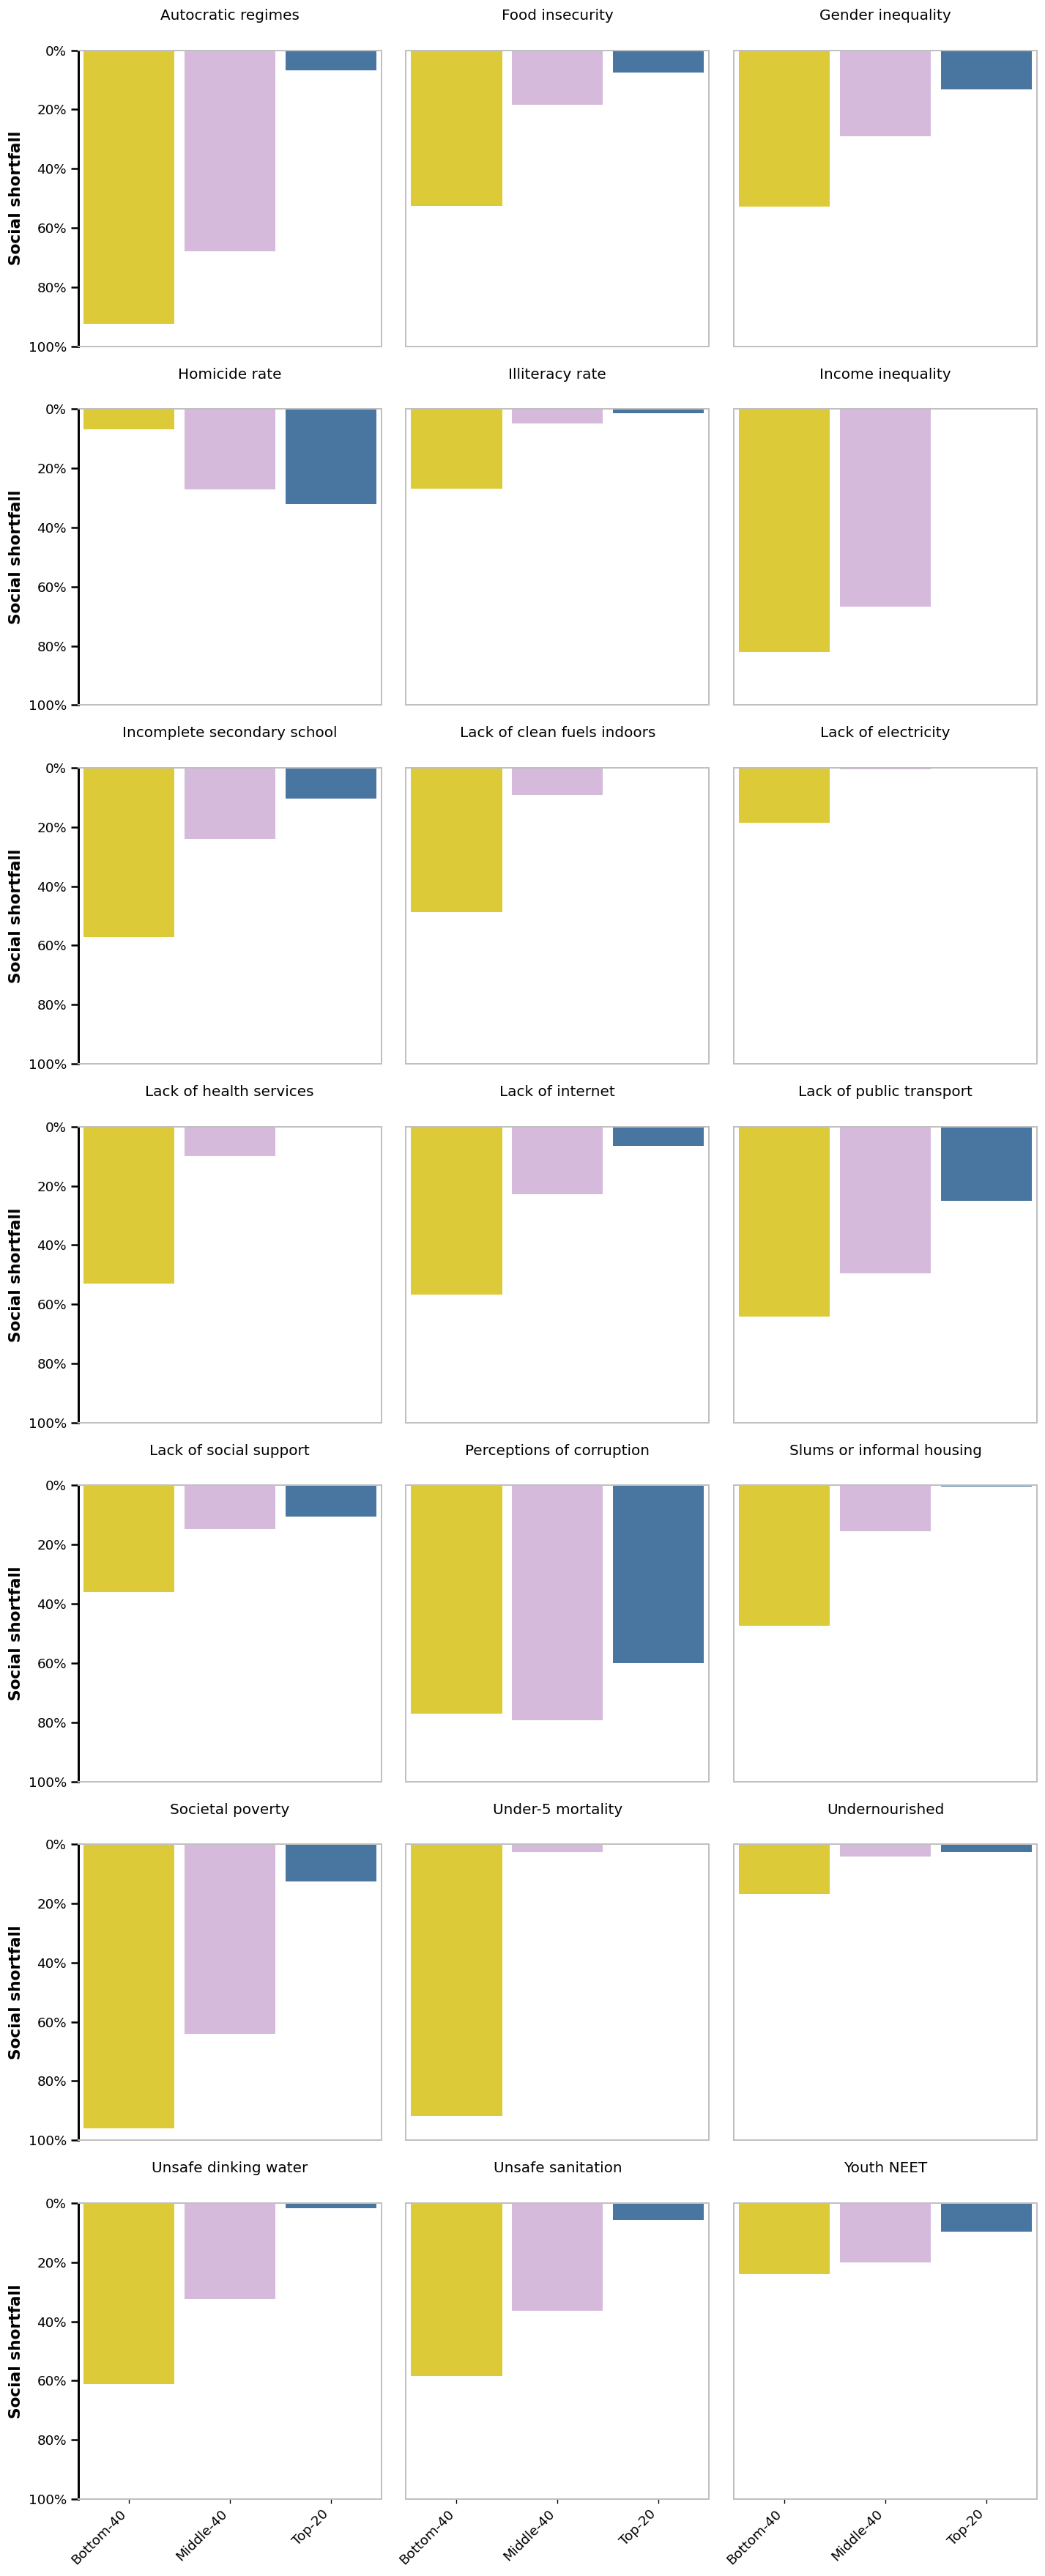

In [1364]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import warnings
warnings.simplefilter("ignore", FutureWarning)

df = cluster_soc_combination.copy()

order = ["Bottom-40", "Middle-40", "Top-20"]
df["group"] = pd.Categorical(df["group"], categories=order, ordered=True)

df["value_plot"] = df["value_last"]  
df["value_plot_visible"] = df["value_plot"]

indicators = sorted(df["indicator"].unique())
n = len(indicators)

if n == 0:
    raise ValueError("No indicators found for plotting.")

# grid layout
ncols = 3
nrows = (n + ncols - 1) // ncols

# Plot setting
plt.rcParams["figure.dpi"] = 120
fig, axes = plt.subplots(nrows, ncols, figsize=(12, nrows * 4.2), constrained_layout=False)
axes = axes.flatten()

colors = ["#F7DF1E", "#D8B4E2", "#3A75B0"]

def percent_fmt(x, pos):
    return f"{int(x)}%"

# Trellis loop
for idx_ax, (ax, ind) in enumerate(zip(axes, indicators)):

    sub = df[df["indicator"] == ind].sort_values("group")

    sns.barplot(
        data=sub,
        x="group",
        y="value_plot_visible",
        ax=ax,
        palette=colors,
        width=0.9
    )

    for spine in ax.spines.values():
        spine.set_edgecolor("#C0C0C0")
        spine.set_linewidth(1.2)

    # show group labels only on last row
    row_index = idx_ax // ncols
    last_row  = nrows - 1

    if row_index == last_row:
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=45, ha="right", fontsize=11)
    else:
        ax.set_xticks([])
        ax.set_xticklabels([])

    # remove automatic label
    ax.set_xlabel("")

    # indicator title
    ax.set_title(ind, fontsize=12, pad=25, color="black")

    # y axis settings
    if idx_ax % ncols == 0:
        ax.set_ylabel("Social shortfall", fontsize=13, fontweight="bold", color="black")
        ax.spines["left"].set_edgecolor("black")
        ax.spines["left"].set_linewidth(1.8)
        ax.yaxis.set_major_formatter(FuncFormatter(percent_fmt))
        ax.tick_params(axis='y', colors='black', labelsize=11, width=1.5, length=6)
    else:
        ax.set_ylabel("")
        ax.set_yticks([])

    ax.set_ylim(100, 0) 

# remove unused axes
for ax in axes[n:]:
    ax.remove()

plt.subplots_adjust(
    hspace=0.20,
    wspace=0.15,
    left=0.08,
    right=0.98,
    top=0.90,
    bottom=0.08
)

plt.tight_layout()

plt.savefig("trellis_social.png", dpi=80, bbox_inches="tight")

plt.show()


## Sandwitch

- Load data
- Data cleaning
- Split the dataset into two subsets
    - Ecological indicators
    - Social indicators

In [1365]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sandwich_data = pd.read_csv("12_20250515_globalDoughnutData_2000-2022.csv")

sandwich_data_clean = (
    sandwich_data
    .drop(columns=["type", "dimension", "group", "grpCode", "indCode", "unit", "value", "boundary"])
    .dropna(subset=["shortfallOvershoot_pct"])
)
# sandwich_data_clean

eco_sandwich = sandwich_data_clean[sandwich_data_clean["domain"] == "ecological"].copy()
social_sandwich = sandwich_data_clean[sandwich_data_clean["domain"] == "social"].copy()
# eco_sandwich, social_sandwich
# eco_sandwich["indicator"].unique()


*Preparing Ecological Data*
- Decode indicator column
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns
- Sort by indicator → date
- Exact first and last values for each indicator
- Merge first and last values

In [1366]:
decode_indicator_eco_sandwich = {
    "co2_ppm" : "CO2 concentration",
    "erf_wm2" : "Radioactive forcing",
    "omega_a" : "Aragonite saturation",
    "nitrogenMt" : "Nitrogen polution",
    "phosphorusMt" : "Phosphorus polution",
    "interhemAOD" : "Aerosol optical depth",
    "extinction1900" : "Species extictions",
    "chemicalsMt_Hzd" : "Hazardous chemical production" ,
    "forestAreaMKM2" : "Forest area",
    "hanppGtC" : "Human appropriation of net primary production",
    "blueDev" : "Blue-water flows",
    "soilDev" : "Soil moisture",
    "totalOzone" : "Stratosperic ozone concentration"
}

eco_sandwich["indicator"] = eco_sandwich["indicator"].map(decode_indicator_eco_sandwich)
eco_sandwich

eco_sandwich = eco_sandwich.sort_values(["indicator", "date"])

eco_first = (
    eco_sandwich
    .groupby("indicator")
    .first()
    .reset_index()
    .rename(columns={"shortfallOvershoot_pct": "shortfall_first"})
)

eco_last = (
    eco_sandwich
    .groupby("indicator")
    .last()
    .reset_index()
    .rename(columns={"shortfallOvershoot_pct": "shortfall_last"})
)

eco_first_last = eco_first.merge(
    eco_last[["indicator", "shortfall_last"]],
    on="indicator"
)

eco_first_last


,indicator,domain,date,shortfall_first,shortfall_last
0,Aerosol optical depth,ecological,2000,-28.6,-28.6
1,Aragonite saturation,ecological,2000,-34.2,-5.2
2,Blue-water flows,ecological,2000,74.8,82.3
3,CO2 concentration,ecological,2000,27.1,95.8
4,Forest area,ecological,2000,54.4,60.9
5,Hazardous chemical production,ecological,2000,1413.9,3214.5
6,Human appropriation of net primary production,ecological,2000,161.2,204.5
7,Nitrogen polution,ecological,2000,113.3,213.4
8,Phosphorus polution,ecological,2000,118.5,273.7
9,Radioactive forcing,ecological,2000,76.8,191.5


*Preparing Social Data*
- Decode indicator column
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns
- Sort by indicator → date
- Exact first and last values for each indicator
- Merge first and last values

In [1367]:
decode_indicator_soc_sandwich = {
    "govRegimes": "Autocratic regimes",
    "foodInsecurity": "Food insecurity",
    "genderInequalityIndex": "Gender inequality",
    "homicideOver5": "Homicide rate",
    "adultLiteracy": "Illiteracy rate",
    "palma": "Income inequality",
    "secondarySchool" : "Incomplete secondary school",
    "energyIndoor" : "Lack of clean fuels indoors",
    "energyAccess" : "Lack of electricity",
    "UHCindex": "Lack of health services",
    "internet" : "Lack of internet",
    "publicTrans" : "Lack of public transport",
    "socialSupport" : "Lack of social support",
    "controlCorruption" : "Perceptions of corruption",
    "urbanSlums" : "Slums or informal housing",
    "societalPoverty" : "Societal poverty", 
    "under5death" : "Child mortality",
    "undernourishment" : "Undernourished",
    "drinkingH2O" : "Unsafe dinking water",
    "sanitation" : "Unsafe sanitation",
    "youthNEET" : "Youth unemployment"
}

social_sandwich["indicator"] = social_sandwich["indicator"].map(decode_indicator_soc_sandwich)
social_sandwich

social_sandwich = social_sandwich.sort_values(["indicator", "date"])

soc_first = (
    social_sandwich
    .groupby("indicator")
    .first()
    .reset_index()
    .rename(columns={"shortfallOvershoot_pct": "shortfall_first"})
)

soc_last = (
    social_sandwich
    .groupby("indicator")
    .last()
    .reset_index()
    .rename(columns={"shortfallOvershoot_pct": "shortfall_last"})
)

soc_first_last = soc_first.merge(
    soc_last[["indicator", "shortfall_last"]],
    on="indicator"
)

soc_first_last


,indicator,domain,date,shortfall_first,shortfall_last
0,Autocratic regimes,social,2000,46.6,70.8
1,Child mortality,social,2000,75.4,42.6
2,Food insecurity,social,2015,22.2,29.4
3,Gender inequality,social,2000,45.7,34.7
4,Homicide rate,social,2000,28.5,19.5
5,Illiteracy rate,social,2000,23.1,16.2
6,Income inequality,social,2000,71.3,64.7
7,Incomplete secondary school,social,2000,60.9,36.9
8,Lack of clean fuels indoors,social,2000,50.5,25.9
9,Lack of electricity,social,2000,21.7,8.5


*Sandwich Plot*
- Calculate increase and reduction (def)
- Apply the function to:
    - eco_first_last → eco_final
    - soc_first_last → soc_final
- Sort indicators
- Plot Sandwich
    - Set up a figure with two stacked subplots:
        - Top: Ecological overshoot (ax1)
        - Bottom: Social shortfall (ax2)
- Save sandwich figure as "sandwich_plot.png"

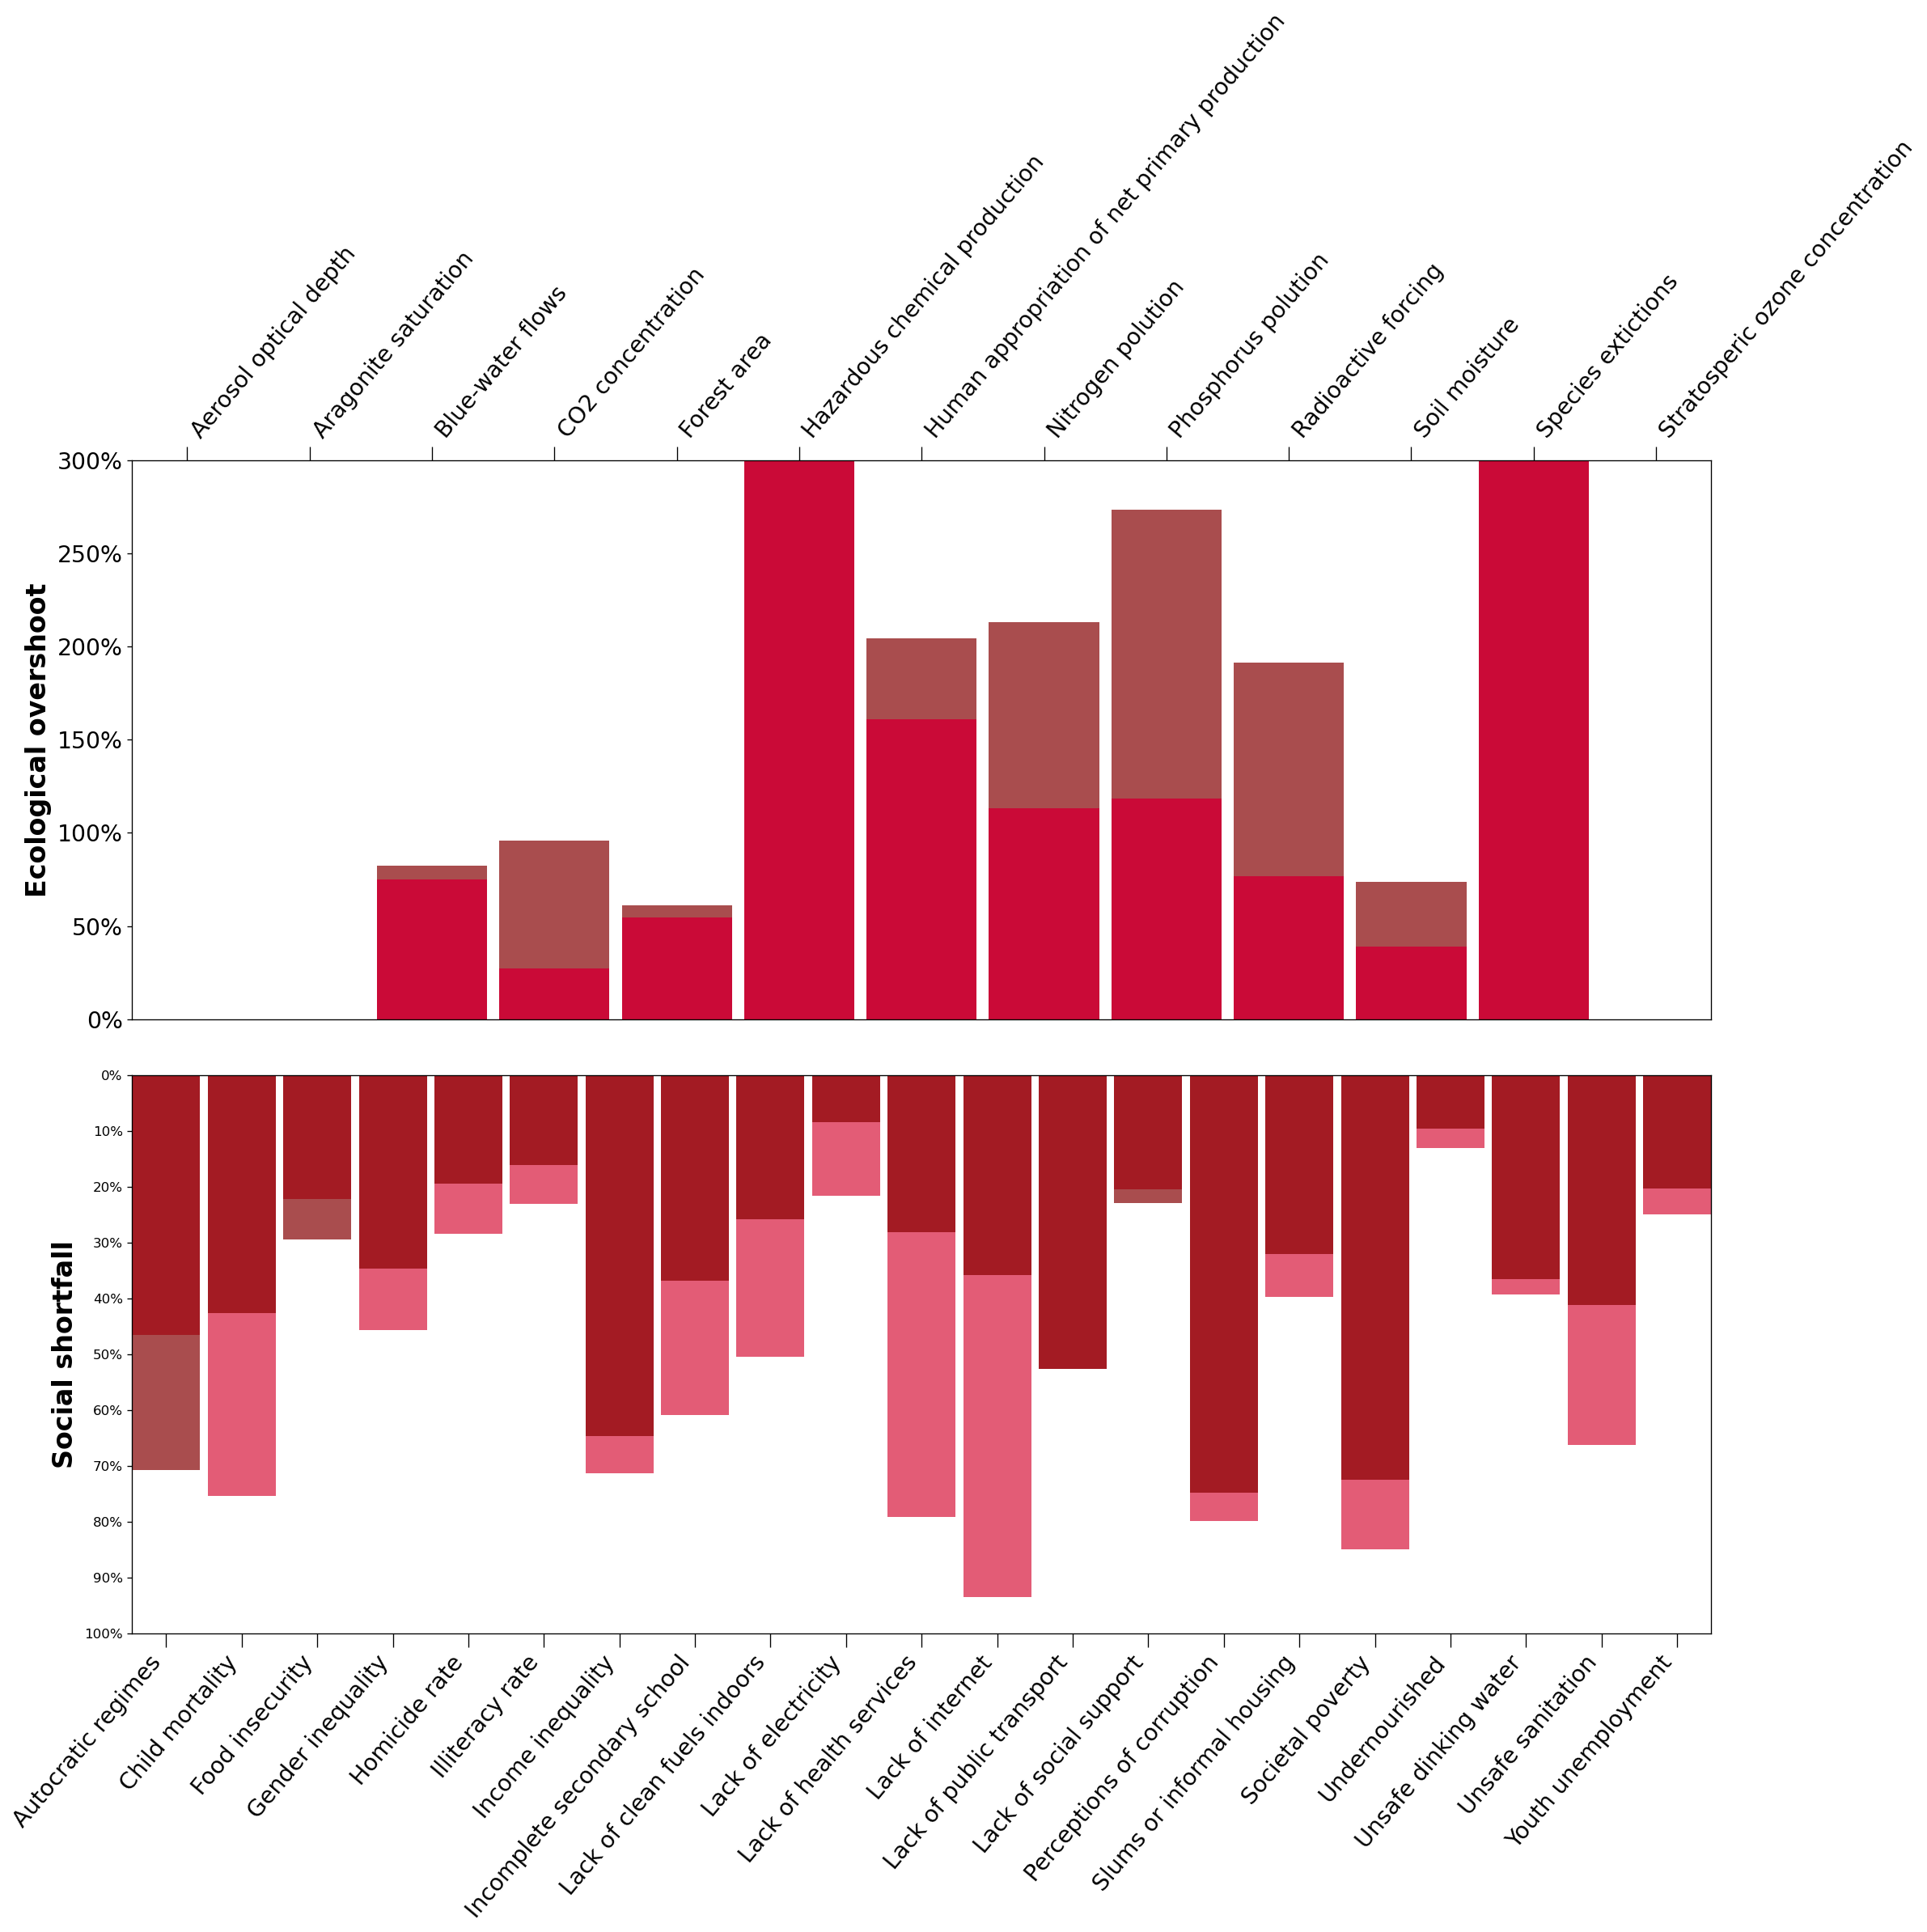

In [1368]:
def compute_change(df):
    df["increase"] = np.where(
        df["shortfall_last"] > df["shortfall_first"],
        df["shortfall_last"] - df["shortfall_first"],
        0
    )
    df["reduction"] = np.where(
        df["shortfall_last"] < df["shortfall_first"],
        df["shortfall_first"] - df["shortfall_last"],
        0
    )
    return df

eco_final = compute_change(eco_first_last)
soc_final = compute_change(soc_first_last)

eco_final = eco_final.sort_values("indicator")
soc_final = soc_final.sort_values("indicator")

# Plot Sandwich
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(20, 20),
    gridspec_kw={'height_ratios': [2, 2]}
)

# Ecological overshoot
x1 = np.arange(len(eco_final))

bar_width = 0.90

# Base
ax1.bar(x1, eco_final["shortfall_first"], width=bar_width, color="#CA0A37")

# Increase = dark red
ax1.bar(x1, eco_final["increase"], bottom=eco_final["shortfall_first"],
        width=bar_width,
        color="#A94D4E")

# Reduction = light red
ax1.bar(
    x1,
    eco_final["reduction"],
    bottom=eco_final["shortfall_first"] - eco_final["reduction"],
    width=bar_width,
    color="#FF758F"
)

ax1.set_xlim(-0.45, len(eco_final) - 0.55)

ax1.set_xticks(x1)
ax1.set_xticklabels(eco_final["indicator"], rotation=50, fontsize=17, ha="left")

# Move x-axis labels + ticks to the TOP
ax1.xaxis.tick_top()
ax1.tick_params(axis="x", labeltop=True, labelbottom=False)
ax1.tick_params(axis="x", which="major", length=10, width=0.8) 

ax1.set_ylabel("Ecological overshoot", weight="bold", fontsize=20)
ax1.set_title("")
ax1.set_ylim(0, 300)

yticks1 = np.arange(0, 350, 50) 
ax1.set_yticks(yticks1)
ax1.set_yticklabels([f"{i}%" for i in yticks1])
ax1.tick_params(axis='y', labelsize=17)

# Social Shortfall
x2 = np.arange(len(soc_final))

bar_width = 0.90

# Base (downward)
ax2.bar(x2, -soc_final["shortfall_first"], width=bar_width,  color="#A31B23")

# Increase (worse) = dark red
ax2.bar(x2, -soc_final["increase"], bottom=-soc_final["shortfall_first"],
        width=bar_width,
        color="#A94D4E")

# Reduction (better) = light red
ax2.bar(
    x2,
    -soc_final["reduction"],
    bottom=-(soc_final["shortfall_first"] - soc_final["reduction"]),
    width=bar_width,
    color="#E35C76"
)

ax2.set_xlim(-0.45, len(soc_final) - 0.55)

ax2.set_xticks(x2)
ax2.set_xticklabels(soc_final["indicator"], rotation=50, fontsize=17, ha="right")
ax2.tick_params(axis="x", which="major", length=10, width=0.8) 

ax2.set_ylabel("Social shortfall", weight="bold", fontsize=20)
ax2.set_title("")

# Only the scale change
ax2.set_ylim(-100, 0) 
ax2.set_yticks(np.arange(0, -110, -10))
ax2.set_yticklabels([f"{abs(i)}%" for i in np.arange(0, -110, -10)])
ax1.tick_params(axis='y', labelsize=17) 

plt.tight_layout()
plt.subplots_adjust(hspace=0.10)

plt.savefig("sandwich_plot.png", dpi=300, bbox_inches="tight")

plt.show()


## Doughunt

- Load data
- Data cleaning
- Split the dataset into two subsets
    - Ecological indicators
    - Social indicators

In [1369]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

doughunt_data = pd.read_csv("12_20250515_globalDoughnutData_2000-2022.csv")

doughunt_data_clean = (
    doughunt_data
    .drop(columns=["type", "group", "grpCode", "indCode", "unit", "value", "boundary"])
    .dropna(subset=["shortfallOvershoot_pct"])
)

# Split into ecological and social subsets
eco_doughunt = doughunt_data_clean[doughunt_data_clean["domain"] == "ecological"].copy()
social_doughunt = doughunt_data_clean[doughunt_data_clean["domain"] == "social"].copy()


*Preparing Ecological Data*
- Decode indicator column
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns
- Sort by indicator → date
- Exact last available value per indicator
- Define ecological dimension order
- Define custom indicator order inside selected dimensions
- Apply custom order within dimensions
- Apply global dimension order to the dimension column
- Rescale shortfall values by dividing shortfall_last by 100

In [1370]:
decode_indicator_eco_doughunt = {
    "co2_ppm" : "CO2 concentration",
    "erf_wm2" : "Radioactive forcing",
    "omega_a" : "Aragonite saturation",
    "nitrogenMt" : "Nitrogen polution",
    "phosphorusMt" : "Phosphorus polution",
    "interhemAOD" : "Aerosol optical depth",
    "extinction1900" : "Species extictions",
    "chemicalsMt_Hzd" : "Hazardous chemical production" ,
    "forestAreaMKM2" : "Forest area",
    "hanppGtC" : "Human appropriation of net primary production",
    "blueDev" : "Blue-water flows",
    "soilDev" : "Soil moisture",
    "totalOzone" : "Stratosperic ozone concentration"
}

eco_doughunt["indicator"] = eco_doughunt["indicator"].map(decode_indicator_eco_doughunt)
# eco_doughunt

eco_doughunt = eco_doughunt.sort_values(["indicator", "date"])

eco_doughnut_last = (
    eco_doughunt
    .sort_values(["indicator", "date"]) 
    .groupby("indicator", as_index=False)
    .last()  
)

eco_doughnut_last = eco_doughnut_last.rename(columns={"shortfallOvershoot_pct": "shortfall_last"})
eco_doughnut_last

eco_order = [
    "climate change",
    "ocean acidification",
    "chemical pollution",
    "nutrient pollution",
    "air pollution",
    "freshwater disruption",
    "land conversion",
    "biodiversity breakdown",
    "ozone depletion"    
]

custom_order = {
    "biodiversity breakdown": [
        "Species extictions",
        "Human appropriation of net primary production"
    ],
    "nutrient pollution": [
        "Phosphorus polution",
        "Nitrogen polution"
    ]
}

eco_fixed = pd.DataFrame()

for dim in eco_order:
    block = eco_doughnut_last[eco_doughnut_last["dimension"] == dim].copy()

    # If dimension has a custom order → reorder rows
    if dim in custom_order:
        order_list = [x.lower() for x in custom_order[dim]]
        block["indicator_lower"] = block["indicator"].str.lower()
        block = block.set_index("indicator_lower").loc[order_list].reset_index(drop=True)
        block = block.drop(columns=["indicator_lower"], errors="ignore")

    eco_fixed = pd.concat([eco_fixed, block], ignore_index=True)

eco_doughnut_last = eco_fixed.copy()

# ECOLOGICAL ORDER
eco_doughnut_last["dimension"] = pd.Categorical(
    eco_doughnut_last["dimension"],
    categories=eco_order,
    ordered=True
)

eco_doughnut_last = eco_doughnut_last.sort_values("dimension").reset_index(drop=True)
eco_doughnut_last["shortfall_last"] = eco_doughnut_last["shortfall_last"]/100
eco_doughnut_last

,indicator,domain,dimension,date,shortfall_last
0,CO2 concentration,ecological,climate change,2022,0.958
1,Radioactive forcing,ecological,climate change,2022,1.915
2,Aragonite saturation,ecological,ocean acidification,2022,-0.052
3,Hazardous chemical production,ecological,chemical pollution,2022,32.145
4,Phosphorus polution,ecological,nutrient pollution,2022,2.737
5,Nitrogen polution,ecological,nutrient pollution,2022,2.134
6,Aerosol optical depth,ecological,air pollution,2022,-0.286
7,Blue-water flows,ecological,freshwater disruption,2022,0.823
8,Soil moisture,ecological,freshwater disruption,2022,0.735
9,Forest area,ecological,land conversion,2022,0.609


*Preparing Social Data*
- Decode indicator column
    - Create a decoding dictionary
    - Map the dictionary to the indicator columns
- Exact last available value per indicator
- Rename the shortfall column

In [1371]:
decode_indicator_soc_doughunt = {
    "govRegimes": "Autocratic regimes",
    "foodInsecurity": "Food insecurity",
    "genderInequalityIndex": "Gender inequality",
    "homicideOver5": "Homicide rate",
    "adultLiteracy": "Illiteracy rate",
    "palma": "Income inequality",
    "secondarySchool" : "Incomplete secondary school",
    "energyIndoor" : "Lack of clean fuels indoors",
    "energyAccess" : "Lack of electricity",
    "UHCindex": "Lack of health services",
    "internet" : "Lack of internet",
    "publicTrans" : "Lack of public transport",
    "socialSupport" : "Lack of social support",
    "controlCorruption" : "Perceptions of corruption",
    "urbanSlums" : "Slums or informal housing",
    "societalPoverty" : "Societal poverty", 
    "under5death" : "Child mortality",
    "undernourishment" : "Undernourished",
    "drinkingH2O" : "Unsafe dinking water",
    "sanitation" : "Unsafe sanitation",
    "youthNEET" : "Youth unemployment"
}

social_doughunt["indicator"] = social_doughunt["indicator"].map(decode_indicator_soc_doughunt)
social_doughunt

# Identify the **last occurrence** of each indicator
mask_last = ~social_doughunt["indicator"].duplicated(keep="last")

soc_doughnut_last = social_doughunt[mask_last].copy()

soc_doughnut_last = soc_doughnut_last.rename(
    columns={"shortfallOvershoot_pct": "shortfall_last"}
)
soc_doughnut_last


,domain,dimension,indicator,date,shortfall_last
321,social,food,Undernourished,2022,9.6
344,social,food,Food insecurity,2022,29.4
367,social,health,Child mortality,2022,42.6
390,social,health,Lack of health services,2022,28.1
413,social,education,Illiteracy rate,2022,16.2
436,social,education,Incomplete secondary school,2022,36.9
459,social,income and work,Societal poverty,2022,72.5
482,social,income and work,Youth unemployment,2022,20.3
505,social,water,Unsafe dinking water,2022,36.6
528,social,water,Unsafe sanitation,2022,41.2


*Plotting Doughnut*
- Set global geometry
    - Define constant radii for:
        - Inner empty hole
        - Social wedges
        - Social rings and ecological outer bars
    - Compute wedge heights for social and ecological layers

In [1372]:
import plotly.graph_objects as go
import numpy as np
import pandas as pd
import math

R_EMPTY            = 0.00   
R_SOC_WEDGE_IN     = 0.35
R_SOC_WEDGE_OUT    = 0.72

R_SOC_RING_OUT     = 0.88   
R_ECO_WEDGE_OUT    = 2.80   

SOC_WEDGE_HEIGHT   = R_SOC_WEDGE_OUT - R_SOC_WEDGE_IN  
ECO_WEDGE_HEIGHT   = R_ECO_WEDGE_OUT     

- Prepare Social indicator ordering:
    - map each social indicator to a broader social dimension
    - define custom dimension order
    - assign the dimension column from the indicator mapping and reorder rows according to social_order
- Compute social wedge heights & angular layout:
    - use shortfall_last as the basis for wedge heights
    - rescale values to fit within the social wedge radial band
    - compute a dimension-based angular layout:
        - each social dimension gets an angular block proportional to its number of indicators
        - a fixed angular gap (GAP) is inserted between dimensions
    - store for each indicator:
        - center angle
        - angular width
- Social wedge colors & hover text
- Draw social background & wedges (inner magenta-like layer)
- Compute social dimension label positions
- Add social foundation ring & title text
- Add social dimension labels (middle ring)
- Add ecological ceiling ring & title text
- Add a helper function to curved text 
- Prepare ecological data for outer bars:
    - clip negative values and apply a square-root transform to compress large values
    - rescale heights to fill the radial space between the ecological ceiling ring and the maximum ecological radius
- Ecological angular layout with dimension gaps: 
    - count indicators per ecological dimension
    - define an ecological gap (ECO_GAP) between dimensions
    - allocate angular blocks per dimension proportional to their number of indicators
    - store for each indicator:
        - center angle
        - angular width
- Draw ecological outer bars
- Add ecological dimension labels
- Final layout & axes cleanup


In [1373]:
soc = soc_doughnut_last.copy()

mapping_soc = {
    "Undernourished": "food",
    "Food insecurity": "food",

    "Child mortality": "health",
    "Lack of health services": "health",

    "Illiteracy rate": "education",
    "Incomplete secondary school": "education",

    "Societal poverty": "income & work",
    "Youth unemployment": "income & work",   

    "Unsafe dinking water": "water",
    "Unsafe sanitation": "water",

    "Lack of electricity": "energy",
    "Lack of clean fuels indoors": "energy",

    "Lack of public transport": "connectivity",
    "Lack of internet": "connectivity",

    "Slums or informal housing": "housing",

    "Gender inequality": "equality",

    "Lack of social support": "social cohesion",
    "Income inequality": "social cohesion",

    "Autocratic regimes": "political voice",

    "Perceptions of corruption": "peace & justice",
    "Homicide rate": "peace & justice"
}

soc["dimension"] = soc["indicator"].map(mapping_soc)
soc["dimension"] = soc["dimension"].str.strip()

social_order = [
    "food",
    "health",
    "education",
    "income & work",
    "peace & justice",
    "political voice",
    "social cohesion",
    "equality",
    "housing",
    "connectivity",
    "energy",
    "water"
]

ordered_soc = []
for dim in social_order:
    ordered_soc.append(soc[soc["dimension"] == dim].copy())

soc = pd.concat(ordered_soc, ignore_index=True)

# heights (inward)
soc_val    = soc["shortfall_last"].clip(lower=0)
soc_sqrt = soc_val
SOC_WEDGE_HEIGHT = R_SOC_WEDGE_OUT - R_SOC_WEDGE_IN
soc_height = soc_sqrt / soc_sqrt.max() * SOC_WEDGE_HEIGHT

N_soc = len(soc)

counts = soc["dimension"].value_counts()

# Gap between social dimensions
GAP = 1.5

total_gap = GAP * len(social_order)
usable_angle = 360 - total_gap

# Angle allocated to each dimension
dim_angle = {}
for dim in social_order:
    dim_angle[dim] = counts[dim] / N_soc * usable_angle

thetas = []
widths = []

current_angle = 0

for dim in social_order:
    k = counts[dim]     
    block = dim_angle[dim] 

    w = block / k 

    subset = soc[soc["dimension"] == dim]

    for i in range(k):
        theta = (90 - (current_angle + w/2)) % 360
        thetas.append(theta)
        widths.append(w)

        current_angle += w

    current_angle += GAP

soc["theta"] = thetas
soc_widths = widths

soc_hover = (
    "<b>" + soc["indicator"] + "</b><br>" +
    "Shortfall: " + soc["shortfall_last"].round(2).astype(str) + "%"
)

social_colorscale="burg"

burg_colors = [
    "#FFC6C4",
    "#F4A3A8",
    "#E38191",
    "#CC607D",
    "#AD466C",
    "#8B3058",
    "#672044",
]

burg_custom = [
    [0.00, burg_colors[0]],
    [0.05, burg_colors[1]],
    [0.12, burg_colors[2]],
    [0.22, burg_colors[3]],
    [0.30, burg_colors[4]],
    [0.40, burg_colors[5]],
    [1.00, burg_colors[6]],
]

eco_colorscale = burg_custom

soc_color_val = soc_val / soc_val.max() if soc_val.max() > 0 else soc_val

fig = go.Figure()

# Backgroud band
light_pink_color = "#f9f4f3"
pink_r = -(R_SOC_WEDGE_OUT - R_EMPTY)  # from wedge outer edge → center
fig.add_trace(go.Barpolar(
    r=np.full(N_soc, pink_r),
    theta=soc["theta"],
    base=np.full(N_soc, R_SOC_WEDGE_OUT),
    width=soc_widths,
    marker=dict(
        color=light_pink_color,
        line=dict(color="rgba(0,0,0,0)", width=0)
    ),
    hoverinfo="skip",
    opacity=1.0
))

soc_base = np.full(N_soc, R_SOC_WEDGE_OUT)
soc_r    = -soc_height

fig.add_trace(go.Barpolar(
    r=soc_r,
    theta=soc["theta"],
    base=soc_base,
    width=soc_widths,
    marker=dict(
        color=soc_color_val,
        colorscale=social_colorscale,
        line=dict(color="rgba(0,0,0,0)", width=0)   # invisible borders
    ),
    customdata=soc_hover,
    hovertemplate="%{customdata}<extra></extra>",
))

# Social dimension label angles
social_dim_angles = []
for dim in social_order:
    block_theta = soc.loc[soc["dimension"] == dim, "theta"].values
    dim_angle = np.degrees(np.arctan2(
        np.mean(np.sin(np.radians(block_theta))),
        np.mean(np.cos(np.radians(block_theta)))
    )) % 360
    social_dim_angles.append(dim_angle)

# Rings
def add_ring(fig, r_inner, r_outer, color):
    """
    Draws a smooth ring (donut band) with no segmentation.
    """
    thetas = np.linspace(0, 360, 361)
    r_outer_arr = np.full_like(thetas, r_outer)
    r_inner_arr = np.full_like(thetas, r_inner)

    fig.add_trace(go.Scatterpolar(
        r=np.concatenate([r_outer_arr, r_inner_arr[::-1]]),
        theta=np.concatenate([thetas, thetas[::-1]]),
        mode='lines',
        fill='toself',
        fillcolor=color,
        line=dict(width=0),
        hoverinfo='skip'
    ))

# Ring right outside social wedges
DARK_RING_THICKNESS = 0.10
R_SOC_RING_OUT = R_SOC_WEDGE_OUT + DARK_RING_THICKNESS 

add_ring(
    fig,
    r_inner=R_SOC_WEDGE_OUT,
    r_outer=R_SOC_RING_OUT,
    color="#227343"
)

# Middle ring (social dimensions)
R_SOC_LIGHT_RING_OUT = 0.98

add_ring(
    fig,
    r_inner=R_SOC_RING_OUT,
    r_outer=R_SOC_LIGHT_RING_OUT,
    color="#6EB348"
)

# Social dimension labels (in middle ring)
pretty_social_labels = []
for dim in social_order:
    clean = dim.strip()
    if "&" in clean:
        parts = [p.strip() for p in clean.replace("&", " & ").split() if p.strip()]
        row1 = parts[0]
        row2 = " ".join(parts[1:])
        label = row1 + "<br>" + row2
    else:
        parts = clean.split()
        if len(parts) == 1:
            label = parts[0]
        else:
            label = "<br>".join(parts)
    pretty_social_labels.append(label)

# radius (polar) for labels
label_radius  = (R_SOC_RING_OUT + R_SOC_LIGHT_RING_OUT) / 2
label_r_paper = label_radius / R_ECO_WEDGE_OUT * 0.5

for label, ang in zip(pretty_social_labels, social_dim_angles):
    theta = np.deg2rad(ang)

    x = 0.5 + label_r_paper * np.cos(theta)
    y = 0.5 + label_r_paper * np.sin(theta)

    textangle = 90 - ang
    if textangle > 90: textangle -= 180
    if textangle < -90: textangle += 180

    fig.add_annotation(
        x=x, y=y,
        text=f"<b>{label}</b>",
        showarrow=False,
        xref="paper", yref="paper",
        font=dict(
            family="Georgia", 
            size=8,
            color="white"
        ),
        textangle=textangle,
        align="center",
        xanchor="center",
        yanchor="middle"
    )

# Outer ring (Ecological Ceiling)
R_ECO_DARK_IN  = R_SOC_LIGHT_RING_OUT
R_ECO_DARK_OUT = R_ECO_DARK_IN + 0.10

add_ring(
    fig,
    r_inner=R_ECO_DARK_IN,
    r_outer=R_ECO_DARK_OUT,
    color="#227343"
)

# curved text: "ECOLOGICAL CEILING" 
eco_label_radius = (R_ECO_DARK_IN + R_ECO_DARK_OUT) / 2
eco_r_paper      = eco_label_radius / R_ECO_WEDGE_OUT * 0.5

start_angle = 120
end_angle   = 55
text = "ECOLOGICAL CEILING"

angles = np.linspace(start_angle, end_angle, len(text))

for ch, ang in zip(text, angles):
    theta = np.deg2rad(ang)

    x = 0.5 + eco_r_paper * np.cos(theta)
    y = 0.5 + eco_r_paper * np.sin(theta)

    textangle = 90 - ang
    if textangle > 90: textangle -= 180
    if textangle < -90: textangle += 180

    fig.add_annotation(
        x=x, y=y,
        text=f"<b>{ch}</b>",
        xref="paper", yref="paper",
        showarrow=False,
        font=dict(
            family="Georgia",
            size=8,
            color="white",
            variant="small-caps"
        ),
        xanchor="center", yanchor="middle",
        textangle=textangle
    )

# helper for curved text (SOCIAL FOUNDATION)
def add_curved_text(fig, text, radius, start_angle, end_angle, color="white", size=12):
    r = radius / R_ECO_WEDGE_OUT * 0.5
    angles = np.linspace(start_angle, end_angle, len(text))

    for ch, ang in zip(text, angles):
        theta = np.deg2rad(ang)
        x = 0.5 + r * np.cos(theta)
        y = 0.5 + r * np.sin(theta)

        text_angle = 90 - ang

        fig.add_annotation(
            x=x,
            y=y,
            text=f"<b>{ch}</b>",
            showarrow=False,
            xref="paper",
            yref="paper",
            font=dict(
                family="Georgia",
                size=size,
                color=color,
                variant="small-caps"
            ),
            textangle=text_angle,
            xanchor="center",
            yanchor="middle"
        )

label_radius = (R_SOC_WEDGE_OUT + R_SOC_RING_OUT) / 2
add_curved_text(
    fig=fig,
    text="SOCIAL FOUNDATION",
    radius=label_radius,
    start_angle=120,
    end_angle=55,
    color="white",
    size=8
)

# Ecological plot (outer plot)
eco = eco_doughnut_last.copy()

eco_val  = eco["shortfall_last"].clip(lower=0)
eco_sqrt = np.sqrt(eco_val)

# right after ecological ceiling ring
ECO_WEDGE_HEIGHT = R_ECO_WEDGE_OUT - R_ECO_DARK_OUT  # available radial space
if eco_sqrt.max() > 0:
    eco_height = eco_sqrt / eco_sqrt.max() * ECO_WEDGE_HEIGHT
else:
    eco_height = eco_sqrt

N_eco = len(eco)

eco_counts = eco["dimension"].value_counts()

# ecological gap
ECO_GAP = 2

total_eco_gap = ECO_GAP * len(eco_order)
usable_eco_angle = 360 - total_eco_gap

# angle allocated per dimension
eco_dim_angle = {
    dim: eco_counts[dim] / N_eco * usable_eco_angle
    for dim in eco_order
}

eco_thetas = []
eco_widths = []

eco_current_angle = 0

for dim in eco_order:
    k = eco_counts[dim] 
    block = eco_dim_angle[dim]  
    w = block / k     

    subset = eco[eco["dimension"] == dim]

    for i in range(k):
        theta = (90 - (eco_current_angle + w/2)) % 360
        eco_thetas.append(theta)
        eco_widths.append(w)
        eco_current_angle += w

    eco_current_angle += ECO_GAP 

eco["theta"] = eco_thetas
eco_widths = eco_widths

eco_hover = (
    "<b>" + eco["indicator"] + "</b><br>" +
    "Shortfall: " + eco["shortfall_last"].round(2).astype(str) + "%"
)

eco_color_val = eco_val / eco_val.max() if eco_val.max() > 0 else eco_val

fig.add_trace(go.Barpolar(
    r=eco_height,
    theta=eco["theta"],
    base=np.full(N_eco, R_ECO_DARK_OUT),
    width=eco_widths,
    marker=dict(
        color=eco_color_val,
        colorscale=eco_colorscale,
        line=dict(color="white", width=1)
    ),
    customdata=eco_hover,
    hovertemplate="%{customdata}<extra></extra>",
))

# Ecological dimension labels
dimension_angles = []

for dim in eco_order:
    block_thetas = eco.loc[eco["dimension"] == dim, "theta"].values
    dim_angle = np.mean(block_thetas) % 360   # exact center of the indicators
    dimension_angles.append(dim_angle)

pretty_labels = []
for dim in eco_order:
    parts = dim.split()
    if len(parts) == 2:
        pretty_labels.append(parts[0] + "<br>" + parts[1])
    else:
        pretty_labels.append(dim)

# Label radius
label_r = 0.43

for label, ang in zip(pretty_labels, dimension_angles):

    theta_rad = np.deg2rad(ang)

    x = 0.5 + 0.5 * label_r * math.cos(theta_rad)
    y = 0.5 + 0.5 * label_r * math.sin(theta_rad)

    textangle = 90 - ang
    
    # keep text readable
    if textangle > 90:
        textangle -= 180
    elif textangle < -90:
        textangle += 180

    # Flip orientation only for these dimensions
    if label in ["chemical<br>pollution", "land<br>conversion"]:
        textangle += 180

    color_label = "black"
    if label in ["chemical<br>pollution"]:
        color_label="white"

    fig.add_annotation(
        x=x,
        y=y,
        text="<b>"+label+"</b>",
        showarrow=False,
        xref="paper",
        yref="paper",
        font=dict(
            family="Georgia",
            size=8,
            color=color_label
        ),
        textangle=textangle,
        align="center",
        xanchor="center",  
        yanchor="middle"   
    )

# Clean layout
fig.update_traces(
    selector=dict(type="barpolar"),
    marker_line_width=0,
    marker_line_color="rgba(0,0,0,0)"
)

fig.update_polars(
    radialaxis=dict(showgrid=False, showline=False, ticks=""),
    angularaxis=dict(showgrid=False, showline=False, ticks="")
)

fig.update_layout(
    template=None,
    polar=dict(
        radialaxis=dict(visible=False, range=[0, R_ECO_WEDGE_OUT]),
        angularaxis=dict(visible=False),
    ),
    showlegend=False,
    width=900,
    height=900,
    margin=dict(l=0, r=0, t=0, b=0),
)

fig.show()
